
# Prediksi Harga Emas Menggunakan Temporal Fusion Transformer (TFT)

## Pembagian Data dan Evaluasi Model

Penelitian ini menggunakan metode *Temporal Fusion Transformer* (TFT) untuk melakukan prediksi harga emas berdasarkan data deret waktu (*time series*). Evaluasi model dilakukan menggunakan data validasi yang dipisahkan secara kronologis dari data pelatihan. Pendekatan ini diterapkan untuk mempertahankan urutan temporal data dan memastikan bahwa evaluasi mencerminkan kemampuan model dalam memprediksi observasi yang belum digunakan selama proses pelatihan.

Pembagian data dan prosedur evaluasi dalam penelitian ini meliputi tahapan berikut:

- **Pembagian data pelatihan dan validasi:** Dataset dibagi secara kronologis dengan proporsi 80% untuk data pelatihan dan 20% untuk data validasi. Data pelatihan digunakan untuk mempelajari pola historis harga emas, sedangkan data validasi digunakan untuk mengevaluasi kinerja model.
- **Penetapan batas prediksi validasi:** Parameter `min_prediction_idx` digunakan untuk menentukan indeks awal target prediksi pada periode validasi. Penetapan ini bertujuan agar target evaluasi berasal dari periode setelah batas data pelatihan.
- **Penggunaan konteks historis:** Observasi historis sebelum periode validasi dapat digunakan sebagai masukan encoder untuk membentuk konteks temporal yang diperlukan model dalam menghasilkan prediksi. Observasi tersebut tidak diperlakukan sebagai target evaluasi validasi.
- **Evaluasi prediksi multi-horizon:** Model TFT dievaluasi menggunakan horizon prediksi sepanjang tujuh langkah pada setiap jendela validasi bergulir (*rolling validation window*).
- **Analisis kinerja setiap horizon:** Hasil evaluasi dipisahkan berdasarkan langkah prediksi H+1 hingga H+7 untuk menganalisis kinerja model pada setiap horizon.

## Model Temporal Fusion Transformer dan Optimasi Hyperparameter

Temporal Fusion Transformer (TFT) digunakan sebagai model utama dalam penelitian ini karena dirancang untuk pemodelan deret waktu yang melibatkan beberapa variabel dan menghasilkan prediksi untuk beberapa horizon sekaligus.

Optimasi hyperparameter dilakukan menggunakan Optuna untuk mencari konfigurasi parameter model yang memberikan kinerja validasi terbaik berdasarkan fungsi objektif yang ditetapkan. Konfigurasi terbaik selanjutnya digunakan dalam proses evaluasi model sesuai dengan rancangan eksperimen penelitian.

## Tujuan Evaluasi

Evaluasi dilakukan untuk mengukur kemampuan model TFT dalam menghasilkan prediksi harga emas pada periode validasi. Pemisahan hasil berdasarkan horizon H+1 hingga H+7 digunakan untuk mengetahui bagaimana kinerja prediksi berubah seiring bertambahnya langkah prediksi.

Hasil evaluasi pada setiap horizon menjadi dasar untuk menganalisis kemampuan model dalam memprediksi harga emas pada jarak prediksi yang berbeda.



## 1. Instalasi dan Persiapan Lingkungan Eksperimen

Tahap ini dilakukan untuk mempersiapkan lingkungan komputasi yang diperlukan dalam implementasi model *Temporal Fusion Transformer* (TFT) dan proses optimasi hyperparameter menggunakan Optuna. Instalasi pustaka dilakukan melalui `pip` dengan memanfaatkan interpreter Python yang aktif pada lingkungan eksperimen.

Pustaka yang digunakan meliputi:

- **PyTorch Forecasting versi 1.8.0:** Digunakan untuk implementasi model TFT dan komponen pendukung pemodelan deret waktu.
- **Lightning versi 2.5 hingga sebelum versi 3.0:** Digunakan untuk mengelola proses pelatihan model, termasuk pengaturan pelatihan dan validasi.
- **Optuna:** Digunakan untuk melakukan optimasi hyperparameter guna mencari konfigurasi model yang memberikan kinerja validasi terbaik.

Instalasi dilakukan menggunakan modul `subprocess` dan `sys` agar perintah instalasi dijalankan melalui interpreter Python yang sedang digunakan. Pendekatan ini membantu memastikan bahwa pustaka dipasang pada lingkungan Python yang sesuai.

Pada tahap ini, NumPy dan Numba bawaan lingkungan komputasi tidak diubah untuk mengurangi risiko konflik dependensi yang dapat mengganggu kestabilan kernel. Apabila instalasi Lightning memerlukan pemuatan ulang lingkungan, sesi atau kernel perlu dimulai ulang sebelum seluruh sel eksperimen dijalankan kembali.

Tahap instalasi ini merupakan persiapan lingkungan sebelum pelaksanaan pemrosesan data, pelatihan model TFT, optimasi hyperparameter, dan evaluasi hasil prediksi harga emas.


In [1]:
# ==============================================================================
# 1. INSTALASI LIBRARY
# ==============================================================================
# Jalankan cell ini satu kali pada sesi Colab/Kaggle baru.
# Cell ini sengaja TIDAK mengganti NumPy/Numba agar kernel tidak crash.
import subprocess
import sys

packages = [
    "pytorch-forecasting==1.8.0",
    "lightning>=2.5,<3",
    "optuna",
]

subprocess.check_call(
    [sys.executable, "-m", "pip", "install", "-q", *packages]
)

print("✅ Library utama tersedia")
print("ℹ️ NumPy dan Numba bawaan environment tidak diubah.")
print("ℹ️ Jika Lightning baru dipasang, restart Session/Kernel satu kali lalu Run All.")


✅ Library utama tersedia
ℹ️ NumPy dan Numba bawaan environment tidak diubah.
ℹ️ Jika Lightning baru dipasang, restart Session/Kernel satu kali lalu Run All.



## 2. Memuat Dataset Penelitian

Tahap ini dilakukan untuk memuat dataset harga emas yang digunakan dalam penelitian prediksi harga emas menggunakan *Temporal Fusion Transformer* (TFT). Dataset disimpan dalam format CSV dengan nama `gold_price_no_idr_update.csv` dan dibaca menggunakan pustaka Pandas.

Proses pemuatan dataset dilakukan melalui tahapan berikut:

- **Penentuan lokasi dataset:** Lokasi berkas ditetapkan menggunakan `Path` dari pustaka `pathlib`, yaitu `/content/gold_price_no_idr_update.csv`, sesuai dengan direktori kerja pada Google Colab.
- **Validasi keberadaan berkas:** Program memeriksa apakah dataset tersedia pada lokasi yang ditentukan. Jika berkas tidak ditemukan, program akan menghentikan eksekusi dan menampilkan pesan kesalahan yang menjelaskan lokasi dataset yang perlu diperiksa.
- **Penentuan direktori keluaran:** Variabel `RUN_OUTPUT_ROOT` ditetapkan ke direktori `/content` sebagai direktori utama penyimpanan hasil eksperimen.
- **Pembacaan dataset:** Fungsi `pd.read_csv()` digunakan untuk membaca berkas CSV dan menyimpan seluruh data ke dalam DataFrame `df` agar dapat diproses pada tahap berikutnya.
- **Pemeriksaan awal dataset:** Program menampilkan lokasi dataset, jumlah baris, jumlah kolom, dan direktori keluaran. Lima baris pertama juga ditampilkan untuk memberikan gambaran awal mengenai struktur dan isi dataset.

Tahap ini memastikan bahwa dataset dapat diakses dan dimuat sebelum dilanjutkan ke proses pemeriksaan kualitas data, prapemrosesan, pembentukan data deret waktu, pelatihan model, dan evaluasi prediksi.

Pemeriksaan pada tahap ini masih bersifat awal. Validasi lebih lanjut terhadap tipe data, nilai yang hilang, duplikasi, urutan waktu, dan karakteristik setiap variabel dilakukan pada tahap pengolahan data sesuai kebutuhan penelitian.


In [2]:

# ==============================================================================
# 2. MEMUAT DATASET - GOOGLE COLAB
# ==============================================================================

from pathlib import Path
import pandas as pd

# Path dataset di Google Colab
file_path = Path("/content/gold_price_no_idr_update.csv")

# Validasi keberadaan dataset
if not file_path.exists():
    raise FileNotFoundError(
        f"Dataset tidak ditemukan: {file_path}\n"
        "Pastikan gold_price_no_idr_update.csv sudah diunggah ke /content."
    )

# Direktori penyimpanan output
RUN_OUTPUT_ROOT = Path("/content")

# Memuat dataset
df = pd.read_csv(file_path)

# Menampilkan informasi dataset
print(f"Dataset     : {file_path}")
print(f"Jumlah baris: {len(df):,}")
print(f"Jumlah kolom: {len(df.columns)}")
print(f"Output root : {RUN_OUTPUT_ROOT}")

display(df.head())


Dataset     : /content/gold_price_no_idr_update.csv
Jumlah baris: 4,289
Jumlah kolom: 73
Output root : /content


,date,open,high,low,close,tickvol,vol,spread,usd_open,usd_high,...,date_dff,vix_open,vix_high,vix_low,vix_close,vix_adj_close,vix_volume,date_vix,gold_ohlc_valid,gold_drive_ohlc_valid
0,2010-01-01,1097.25,1097.90,1097.05,1097.35,NaN,NaN,NaN,NaN,NaN,...,2010-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,True
1,2010-01-04,1096.25,1123.80,1093.45,1120.40,NaN,NaN,NaN,NaN,NaN,...,2010-01-04,21.680000,21.680000,20.030001,20.040001,20.040001,0.0,2010-01-04,True,True
2,2010-01-05,1121.30,1128.10,1115.25,1119.05,NaN,NaN,NaN,NaN,NaN,...,2010-01-05,20.049999,20.129999,19.340000,19.350000,19.350000,0.0,2010-01-05,True,True
3,2010-01-06,1118.40,1140.60,1116.00,1138.90,NaN,NaN,NaN,NaN,NaN,...,2010-01-06,19.590000,19.680000,18.770000,19.160000,19.160000,0.0,2010-01-06,True,True
4,2010-01-07,1138.20,1139.15,1128.60,1132.30,NaN,NaN,NaN,NaN,NaN,...,2010-01-07,19.680000,19.709999,18.700001,19.059999,19.059999,0.0,2010-01-07,True,True



## 3. Import Library dan Konfigurasi Eksperimen

Tahap ini dilakukan dengan mengimpor pustaka yang diperlukan untuk implementasi model *Temporal Fusion Transformer* (TFT), optimasi hyperparameter, pelatihan model, visualisasi, dan evaluasi hasil prediksi harga emas.

- **NumPy:** Digunakan untuk operasi numerik dan pengolahan array. Penyesuaian atribut `np.row_stack` dilakukan apabila atribut tersebut tidak tersedia untuk menjaga kompatibilitas dengan pustaka yang digunakan.
- **Matplotlib:** Digunakan untuk memvisualisasikan hasil eksperimen dan mengatur format tanggal pada grafik.
- **PyTorch:** Digunakan untuk komputasi tensor dan mendukung proses pembelajaran model.
- **PyTorch Forecasting:** Menyediakan `TimeSeriesDataSet` untuk pembentukan dataset deret waktu serta `TemporalFusionTransformer` sebagai implementasi model TFT.
- **Lightning:** Digunakan untuk mengelola proses pelatihan model, termasuk mekanisme `EarlyStopping` untuk menghentikan pelatihan berdasarkan kriteria tertentu dan `ModelCheckpoint` untuk menyimpan checkpoint model.
- **QuantileLoss:** Digunakan sebagai fungsi kerugian dalam pelatihan TFT berbasis prediksi kuantil.
- **EncoderNormalizer:** Digunakan untuk normalisasi target berdasarkan data historis encoder sesuai konfigurasi dataset.
- **Optuna:** Digunakan untuk melakukan optimasi hyperparameter guna mencari konfigurasi model berdasarkan fungsi objektif yang ditentukan.
- **Scikit-learn:** Menyediakan metrik evaluasi, yaitu *Mean Absolute Error* (MAE), *Mean Squared Error* (MSE), dan koefisien determinasi (\(R^2\)).
- **Pickle:** Diimpor untuk mendukung serialisasi objek Python apabila diperlukan.
- **Unittest Mock:** Menyediakan fungsi `patch` untuk mengganti sementara perilaku objek atau fungsi selama eksekusi program.
- **Warnings:** Digunakan untuk mengatur tampilan pesan peringatan selama eksperimen.
- **Random:** Digunakan untuk mengatur bilangan acak Python.

Variabel lingkungan `NUMBA_DISABLE_JIT` diatur ke `1` untuk menonaktifkan kompilasi JIT Numba sebagai langkah kompatibilitas pada lingkungan eksperimen. Pengaturan ini dilakukan tanpa mengganti versi NumPy dan Numba yang telah tersedia.

Untuk mendukung reproduktibilitas eksperimen, nilai *random seed* ditetapkan sebesar `42` dan diterapkan pada Python, NumPy, PyTorch, serta Lightning. Pengaturan tersebut bertujuan meningkatkan konsistensi hasil ketika eksperimen dijalankan kembali dengan konfigurasi dan lingkungan yang sebanding.

Seluruh pustaka dan konfigurasi awal ini digunakan untuk mendukung tahapan pengolahan data, pembentukan dataset, pelatihan TFT, optimasi hyperparameter, dan evaluasi prediksi harga emas.


In [3]:
# ==============================================================================
# 3. IMPORT LIBRARY
# ==============================================================================
import os

# TimeSeriesDataSet hanya memakai Numba sebagai akselerasi opsional.
# Dataset ini kecil, jadi JIT dinonaktifkan untuk mencegah konflik Numba-NumPy
# tanpa mengganti paket inti yang sedang dipakai kernel.
os.environ["NUMBA_DISABLE_JIT"] = "1"

import numpy as np

# Kompatibilitas tambahan untuk Numba lama pada NumPy yang sudah menghapus
# alias row_stack. row_stack memang merupakan alias dari vstack.
if not hasattr(np, "row_stack"):
    np.row_stack = np.vstack

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import torch
import optuna
import lightning.pytorch as pl
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
from pytorch_forecasting import TimeSeriesDataSet, TemporalFusionTransformer, QuantileLoss
from pytorch_forecasting.data import EncoderNormalizer
from unittest.mock import patch
import warnings, random
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
import pickle

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)
pl.seed_everything(SEED)

print(f"✅ Libraries imported successfully | NumPy {np.__version__}")
print("✅ Numba JIT dinonaktifkan untuk kompatibilitas TimeSeriesDataSet")


INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42


✅ Libraries imported successfully | NumPy 2.1.3
✅ Numba JIT dinonaktifkan untuk kompatibilitas TimeSeriesDataSet



## 4. Konfigurasi Kombinasi Hyperparameter dan Perangkat Komputasi

Eksperimen ini dilakukan untuk mengevaluasi pengaruh kombinasi *learning rate* dan *batch size* terhadap kinerja model Temporal Fusion Transformer (TFT) dalam prediksi harga emas. Sebanyak 12 kombinasi parameter disiapkan untuk pengujian dengan nilai *learning rate* sebesar 0,0001; 0,0003; 0,0005; dan 0,001, serta *batch size* sebesar 16, 32, dan 64.

Pemilihan kombinasi eksperimen dilakukan melalui variabel `COMBO_ID`, dengan rentang nilai 1 hingga 12. Setiap ID merepresentasikan pasangan *learning rate* dan *batch size* tertentu. Dengan demikian, kombinasi parameter dapat diubah tanpa perlu mengubah konfigurasi lainnya secara manual.

Variabel `N_TRIALS_OPTUNA` digunakan untuk menentukan jumlah percobaan dalam optimasi hyperparameter menggunakan Optuna. Pada konfigurasi ini, jumlah percobaan ditetapkan sebanyak 50 *trial* untuk mencari konfigurasi parameter tambahan berdasarkan fungsi objektif yang digunakan dalam eksperimen.

Selain konfigurasi hyperparameter, notebook melakukan pemilihan perangkat komputasi secara otomatis berdasarkan ketersediaan perangkat keras. GPU CUDA akan digunakan apabila tersedia. Jika GPU tidak tersedia, program memeriksa kesiapan TPU melalui XLA. Apabila TPU juga tidak tersedia, proses dijalankan menggunakan CPU.

Jumlah perangkat komputasi ditetapkan sebanyak satu perangkat untuk menghindari penggunaan mekanisme peluncuran multi-perangkat yang tidak diperlukan dalam konfigurasi ini. Pengaturan tersebut diterapkan pada konfigurasi trainer prediksi, dengan pencatatan log dinonaktifkan pada trainer tersebut.

Hasil konfigurasi ditampilkan sebelum eksperimen dijalankan, meliputi ID kombinasi, *learning rate*, *batch size*, jumlah *trial* Optuna, catatan konfigurasi, jenis akselerator, jumlah perangkat, dan status kesiapan TPU. Informasi ini digunakan untuk mengidentifikasi konfigurasi eksperimen yang sedang dijalankan serta mendukung pencatatan dan perbandingan hasil antarkombinasi.


**Catatan:** Untuk menjalankan eksperimen dengan kombinasi hyperparameter yang berbeda, cukup ubah nilai `COMBO_ID` pada bagian konfigurasi. Nilai `COMBO_ID` dapat diatur dari 1 hingga 12 sesuai kombinasi *learning rate* dan *batch size* yang ingin diuji. Setelah nilai diubah, jalankan kembali notebook agar eksperimen menggunakan konfigurasi yang sesuai dengan ID yang dipilih. Pastikan hasil setiap kombinasi dicatat secara terpisah untuk memudahkan perbandingan kinerja model.



In [4]:

# ==============================================================================
# 4. KONFIGURASI KOMBINASI LEARNING RATE DAN BATCH SIZE
# ==============================================================================
# Pilih kombinasi eksperimen dengan mengubah nilai COMBO_ID dari 1 hingga 12.
# Setiap ID merepresentasikan kombinasi learning rate dan batch size yang berbeda.
# Hasil setiap eksperimen digunakan untuk membandingkan kinerja model TFT.

EXPERIMENT_GRID = [
    {"id": 1,  "learning_rate": 1e-4, "batch_size": 16, "catatan": "Aman, lambat tapi stabil"},
    {"id": 2,  "learning_rate": 1e-4, "batch_size": 32, "catatan": "Stabil baseline rendah"},
    {"id": 3,  "learning_rate": 1e-4, "batch_size": 64, "catatan": "Stabil, perlu epoch lebih banyak"},

    {"id": 4,  "learning_rate": 3e-4, "batch_size": 16, "catatan": "Cukup stabil"},
    {"id": 5,  "learning_rate": 3e-4, "batch_size": 32, "catatan": "Rekomendasi awal"},
    {"id": 6,  "learning_rate": 3e-4, "batch_size": 64, "catatan": "Cepat kalau GPU kuat"},

    {"id": 7,  "learning_rate": 5e-4, "batch_size": 16, "catatan": "Medium, pantau val loss"},
    {"id": 8,  "learning_rate": 5e-4, "batch_size": 32, "catatan": "Kandidat bagus"},
    {"id": 9,  "learning_rate": 5e-4, "batch_size": 64, "catatan": "Cepat, pantau overfit"},

    {"id": 10, "learning_rate": 1e-3, "batch_size": 16, "catatan": "Agresif"},
    {"id": 11, "learning_rate": 1e-3, "batch_size": 32, "catatan": "Agresif sedang"},
    {"id": 12, "learning_rate": 1e-3, "batch_size": 64, "catatan": "Paling agresif, bisa tidak stabil"},
]

# Pilih ID kombinasi eksperimen yang akan dijalankan.
COMBO_ID = 8

# Tentukan jumlah trial Optuna untuk optimasi hyperparameter lainnya.
N_TRIALS_OPTUNA = 50

# Ambil konfigurasi berdasarkan ID kombinasi yang dipilih.
EXP = next((x for x in EXPERIMENT_GRID if x["id"] == COMBO_ID), None)
if EXP is None:
    raise ValueError("COMBO_ID harus 1 sampai 12")

LEARNING_RATE = float(EXP["learning_rate"])
BATCH_SIZE = int(EXP["batch_size"])

# Tampilkan seluruh kombinasi eksperimen yang tersedia.
combo_df = pd.DataFrame(EXPERIMENT_GRID)
display(combo_df)

# Tampilkan konfigurasi eksperimen yang akan dijalankan.
print("=" * 70)
print(f"ID KOMBINASI      : {COMBO_ID}")
print(f"LEARNING RATE     : {LEARNING_RATE}")
print(f"BATCH SIZE        : {BATCH_SIZE}")
print(f"JUMLAH TRIAL      : {N_TRIALS_OPTUNA}")
print(f"CATATAN           : {EXP['catatan']}")
print("=" * 70)


# ==============================================================================
# KONFIGURASI PERANGKAT KOMPUTASI
# ==============================================================================
# Periksa ketersediaan GPU CUDA dan TPU berbasis XLA.
# Jika GPU tersedia, gunakan GPU; jika tidak, gunakan TPU apabila siap.
# CPU digunakan sebagai alternatif apabila GPU dan TPU tidak tersedia.

TPU_READY = False
TPU_NOTE = "torch_xla tidak tersedia"

try:
    from lightning.fabric.accelerators import XLAAccelerator

    TPU_READY = bool(XLAAccelerator.is_available())
    TPU_NOTE = "XLA siap" if TPU_READY else "XLA/TPU tidak siap"
except (ImportError, ModuleNotFoundError, OSError, RuntimeError) as exc:
    TPU_READY = False
    TPU_NOTE = f"{type(exc).__name__}: {exc}"

# Tentukan akselerator berdasarkan perangkat yang tersedia.
if torch.cuda.is_available():
    HARDWARE_ACCELERATOR = "gpu"
elif TPU_READY:
    HARDWARE_ACCELERATOR = "tpu"
else:
    HARDWARE_ACCELERATOR = "cpu"

# Gunakan satu perangkat komputasi untuk konfigurasi trainer prediksi.
HARDWARE_DEVICES = 1

PREDICT_TRAINER_KWARGS = {
    "accelerator": HARDWARE_ACCELERATOR,
    "devices": HARDWARE_DEVICES,
    "logger": False,
}

# Tampilkan informasi perangkat komputasi yang digunakan.
print(f"AKSELERATOR       : {HARDWARE_ACCELERATOR}")
print(f"JUMLAH PERANGKAT  : {HARDWARE_DEVICES}")
print(f"STATUS TPU        : {TPU_NOTE}")


,id,learning_rate,batch_size,catatan
0,1,0.0001,16,"Aman, lambat tapi stabil"
1,2,0.0001,32,Stabil baseline rendah
2,3,0.0001,64,"Stabil, perlu epoch lebih banyak"
3,4,0.0003,16,Cukup stabil
4,5,0.0003,32,Rekomendasi awal
5,6,0.0003,64,Cepat kalau GPU kuat
6,7,0.0005,16,"Medium, pantau val loss"
7,8,0.0005,32,Kandidat bagus
8,9,0.0005,64,"Cepat, pantau overfit"
9,10,0.0010,16,Agresif


ID KOMBINASI      : 8
LEARNING RATE     : 0.0005
BATCH SIZE        : 32
JUMLAH TRIAL      : 50
CATATAN           : Kandidat bagus
AKSELERATOR       : gpu
JUMLAH PERANGKAT  : 1
STATUS TPU        : XLA/TPU tidak siap



## 5. Data Preprocessing

Tahap *data preprocessing* dilakukan untuk mempersiapkan dataset harga emas sebelum digunakan dalam pemodelan Temporal Fusion Transformer (TFT). Proses ini meliputi pengurutan data berdasarkan waktu, penanganan nilai yang hilang, pembentukan fitur turunan (*feature engineering*), penghapusan observasi yang tidak lengkap, serta penambahan variabel indeks waktu dan informasi kalender.

- **Pengurutan data:** Mengonversi kolom tanggal ke format datetime dan mengurutkan observasi secara kronologis.
- **Penanganan missing values:** Mengisi nilai yang hilang pada variabel eksternal menggunakan metode *forward fill* .
- **Feature engineering:** Membentuk fitur lag, rata-rata bergerak (*moving average*), standar deviasi, transformasi logaritmik, deviasi harga terhadap rata-rata bergerak, perubahan relatif (*return*), dan volatilitas harga emas.
- **Penghapusan data tidak lengkap:** Menghapus baris yang memiliki nilai kosong pada fitur-fitur yang diperlukan dalam pemodelan.
- **Pembentukan variabel waktu:** Membuat `time_idx` sebagai indeks urutan waktu, `group_id` sebagai identitas deret waktu, serta `day_of_week`, `month`, dan `year_num` sebagai variabel yang merepresentasikan informasi kalender.

Setelah proses *data preprocessing* selesai, program menampilkan jumlah observasi yang tersisa, rentang tanggal, dan rentang harga penutupan emas. Hasil tahap ini menjadi dataset yang digunakan pada tahap pembentukan dataset TFT dan pelatihan model.


In [5]:

# ==============================================================================
# 5. DATA PREPROCESSING
# ==============================================================================
print("\n-> Memuat dan memproses dataset...")

# Memuat dataset, mengonversi kolom tanggal, dan mengurutkan data secara kronologis
df = pd.read_csv(file_path)
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

# Menangani missing values pada variabel eksternal menggunakan forward fill
ffill_cols = [
    'oil_dcoilwtico', 'fed_rate_pct', 'fed_target_rate_from_pct',
    'fed_target_rate_to_pct', 'cpi_cpiaucsl',
    'usd_open', 'usd_close', 'usd_adj_close',
    'gspc_open', 'gspc_close',
]
for col in ffill_cols:
    if col in df.columns:
        df[col] = df[col].ffill().bfill()

# Membentuk fitur lag, moving average, dan standar deviasi harga emas
df['close_lag1']  = df['close'].shift(1)
df['close_lag5']  = df['close'].shift(5)
df['close_ma7']   = df['close'].rolling(7).mean()
df['close_ma20']  = df['close'].rolling(20).mean()
df['close_std7']  = df['close'].rolling(7).std()

# Membentuk fitur transformasi logaritmik harga emas dan statistik bergeraknya
df['log_close']   = np.log(df['close'])
df['log_close_lag1'] = df['log_close'].shift(1)
df['log_close_ma7']  = df['log_close'].rolling(7).mean()

# Menghitung deviasi harga emas terhadap moving average 20 periode
df['close_pct_from_ma20'] = (df['close'] - df['close_ma20']) / df['close_ma20']

# Membentuk fitur perubahan relatif harga emas dan variabel eksternal
df['gold_ret1']   = df['close'].pct_change()
df['gold_ret5']   = df['close'].pct_change(5)
df['usd_ret1']    = df['usd_close'].pct_change()
df['gspc_ret1']   = df['gspc_close'].pct_change()
df['oil_ret1']    = df['oil_dcoilwtico'].pct_change()

# Membentuk fitur lag pada variabel USD, minyak, dan S&P 500
df['usd_close_lag1']  = df['usd_close'].shift(1)
df['oil_lag1']        = df['oil_dcoilwtico'].shift(1)
df['gspc_close_lag1'] = df['gspc_close'].shift(1)

# Menghitung volatilitas perubahan harga emas berdasarkan rolling standard deviation
df['gold_vol5']   = df['gold_ret1'].rolling(5).std()
df['gold_vol20']  = df['gold_ret1'].rolling(20).std()

# Menghapus observasi yang memiliki missing values pada fitur yang diperlukan
required_cols = [
    'close_lag1', 'close_lag5', 'close_ma7', 'close_ma20', 'close_std7',
    'log_close', 'log_close_lag1', 'log_close_ma7', 'close_pct_from_ma20',
    'gold_ret1', 'gold_ret5', 'usd_ret1', 'gspc_ret1', 'oil_ret1',
    'usd_close_lag1', 'oil_lag1', 'gspc_close_lag1',
    'gold_vol5', 'gold_vol20',
]
df = df.dropna(subset=required_cols).reset_index(drop=True)

# Membentuk metadata waktu untuk kebutuhan pemodelan Temporal Fusion Transformer
df['time_idx']    = range(len(df))
df['group_id']    = 'XAU_USD'
df['day_of_week'] = df['date'].dt.day_name().astype(str)
df['month']       = df['date'].dt.month.astype(str)
df['year_num']    = (df['date'].dt.year - 2021).astype(float)

# Menampilkan ringkasan hasil data preprocessing
print(f"   Total data      : {len(df)} baris")
print(f"   Rentang tanggal : {df['date'].min().date()} s/d {df['date'].max().date()}")
print(f"   Close range     : ${df['close'].min():.0f} – ${df['close'].max():.0f}")



-> Memuat dan memproses dataset...
   Total data      : 4348 baris
   Rentang tanggal : 2010-01-29 s/d 2026-10-12
   Close range     : $1052 – $5418



## 6. Data Split: Training dan Validation

Pembagian dataset dilakukan secara kronologis dengan rasio 80:20, yaitu 80% data untuk training dan 20% data untuk validation. Sebelum pembagian dilakukan, data diurutkan berdasarkan tanggal untuk mempertahankan urutan temporal dan memastikan tidak terdapat tanggal duplikat.

Pada pemodelan Temporal Fusion Transformer (TFT), digunakan panjang encoder maksimum 60 observasi (*max_encoder_length*) dan horizon prediksi 7 observasi (*max_prediction_length*). Encoder menyediakan informasi historis untuk memprediksi harga emas pada periode berikutnya, sedangkan decoder menghasilkan prediksi untuk horizon yang telah ditentukan.

Dataset training hanya menggunakan data sebelum batas pembagian. Dataset validation dibentuk menggunakan seluruh dataframe dengan parameter `min_prediction_idx` untuk menentukan awal periode target validation. Dengan pendekatan ini, encoder validation dapat menggunakan konteks historis dari data training, tetapi target yang dievaluasi tetap berada pada periode validation.

Penanganan nilai yang hilang pada variabel eksternal dilakukan menggunakan *forward fill* hingga maksimal 5 observasi. Nilai yang masih hilang diisi menggunakan median dari data training. Fitur turunan yang memiliki nilai tidak valid juga ditangani menggunakan median training. Sementara itu, target harga emas (`close`) harus memiliki nilai valid dan tidak diimputasi.

Variabel kalender, yaitu `day_of_week` dan `month`, menggunakan encoder dengan kategori yang ditentukan berdasarkan domain kalender. Hal ini memungkinkan kategori kalender yang belum muncul pada data training tetap dikenali saat validation.

Jumlah baris training dan validation tidak selalu sama dengan jumlah *sequence* yang dihasilkan oleh `TimeSeriesDataSet`. Pembentukan sequence mempertimbangkan panjang encoder, horizon prediksi, dan ketersediaan observasi. Validation menggunakan horizon penuh 7 observasi sehingga hanya sequence dengan target lengkap yang disertakan.


In [6]:

# ==============================================================================
# 6. DATA SPLIT: TRAINING DAN VALIDATION
# ==============================================================================
# Menetapkan panjang encoder dan horizon prediksi untuk model TFT
max_prediction_length = 7
max_encoder_length = 60

# Mengurutkan dataset berdasarkan tanggal dan memastikan tidak ada tanggal duplikat
df = df.copy()
df['date'] = pd.to_datetime(df['date'], errors='raise')
df = df.sort_values('date').reset_index(drop=True)
assert df['date'].is_unique, 'Tanggal emas duplikat.'

# Membentuk indeks waktu berurutan dan menentukan batas pembagian data 80:20
df['time_idx'] = np.arange(len(df), dtype=np.int64)
split_idx = int(len(df) * 0.80)
training_cutoff = split_idx - 1
validation_start_idx = split_idx

# Memastikan jumlah data mencukupi untuk encoder 60 observasi dan horizon 7 observasi
if split_idx < max_encoder_length + max_prediction_length or len(df)-split_idx < max_prediction_length:
    raise ValueError('Data terlalu sedikit untuk encoder 60 dan horizon 7.')

# Menggunakan seri DXY sebagai sumber variabel USD dan mempertahankan
# nama fitur usd_* agar konsisten dengan struktur fitur notebook
if {'dxy_open', 'dxy_close'}.issubset(df.columns):
    df['usd_open'] = pd.to_numeric(df['dxy_open'], errors='coerce')
    df['usd_close'] = pd.to_numeric(df['dxy_close'], errors='coerce')
else:
    raise ValueError('Gunakan CSV hasil gabungan yang memiliki dxy_open dan dxy_close.')

# Memastikan variabel federal funds rate tersedia pada dataset
if 'fed_dff_pct' not in df.columns:
    raise ValueError('Kolom fed_dff_pct tidak ditemukan pada CSV hasil gabungan.')

# Memvalidasi urutan indeks waktu dan memastikan dataset hanya berisi
# satu seri harga emas dengan indeks waktu yang berurutan
df = df.sort_values('time_idx').reset_index(drop=True).copy()
assert df['group_id'].nunique() == 1, 'Blok ini untuk satu seri harga emas.'
assert df['time_idx'].is_unique
assert (df['time_idx'].diff().dropna() == 1).all(), 'time_idx harus berurutan per observasi.'
assert df['date'].is_monotonic_increasing

# Menentukan observasi yang termasuk dalam data training
train_mask = df['time_idx'] <= training_cutoff

# Menangani missing values pada variabel eksternal dengan forward fill
# hingga maksimal 5 observasi, kemudian menggunakan median data training
# sebagai nilai pengganti untuk nilai yang masih hilang
# Menambahkan indikator missing values untuk membedakan nilai asli
# dan nilai yang telah melalui proses imputasi
missing_flags = []
base_features = ['usd_open', 'usd_close', 'gspc_open', 'gspc_close',
                 'oil_dcoilwtico', 'fed_dff_pct']

for col in base_features:
    values = pd.to_numeric(df[col], errors='coerce').replace([np.inf, -np.inf], np.nan)
    flag = f'{col}_missing'
    df[flag] = values.isna().astype(float)
    missing_flags.append(flag)

    historical = values.ffill(limit=5)
    fallback = historical.loc[train_mask].median()

    if not np.isfinite(fallback):
        raise ValueError(f'{col}: tidak ada nilai valid dalam training.')

    df[col] = historical.fillna(fallback)

# Menghitung ulang fitur lag dan perubahan relatif variabel eksternal
# berdasarkan seri USD, S&P 500, dan minyak yang telah dilengkapi
df['usd_close_lag1'] = df['usd_close'].shift(1)
df['usd_ret1'] = df['usd_close'].pct_change(fill_method=None)
df['gspc_close_lag1'] = df['gspc_close'].shift(1)
df['gspc_ret1'] = df['gspc_close'].pct_change(fill_method=None)
df['oil_lag1'] = df['oil_dcoilwtico'].shift(1)
df['oil_ret1'] = df['oil_dcoilwtico'].pct_change(fill_method=None)

# Menetapkan fitur numerik yang digunakan sebagai variabel masukan TFT
# Tick volume tidak disertakan karena tidak tersedia dalam data historis
# CPI tidak disertakan karena informasi tanggal rilisnya tidak tersedia
# untuk memastikan kesesuaian waktu informasi saat prediksi
unknown_reals = [
    'open', 'close',
    'close_lag1', 'close_lag5', 'close_ma7', 'close_ma20', 'close_std7',
    'log_close', 'log_close_lag1', 'log_close_ma7', 'close_pct_from_ma20',
    'gold_ret1', 'gold_ret5', 'gold_vol5', 'gold_vol20',
    'usd_open', 'usd_close', 'usd_close_lag1', 'usd_ret1',
    'gspc_open', 'gspc_close', 'gspc_close_lag1', 'gspc_ret1',
    'oil_dcoilwtico', 'oil_lag1', 'oil_ret1', 'fed_dff_pct',
] + missing_flags

# Memastikan seluruh fitur yang dibutuhkan tersedia sebelum pembentukan dataset TFT
missing_columns = [c for c in unknown_reals if c not in df.columns]
if missing_columns:
    raise ValueError(f'Jalankan feature engineering dahulu. Kolom belum ada: {missing_columns}')

# Memastikan target harga emas merupakan nilai asli yang valid
# dan tidak mengandung NaN maupun nilai tak hingga
target = pd.to_numeric(df['close'], errors='coerce')
if not np.isfinite(target.to_numpy(dtype=float)).all():
    raise ValueError('Target close masih kosong/inf. Perbaiki sumber target terlebih dahulu.')
df['close'] = target

# Menangani sisa NaN dan nilai tak hingga pada fitur numerik
# menggunakan median yang dihitung hanya dari data training
for col in unknown_reals:
    if col == 'close':
        continue

    values = pd.to_numeric(df[col], errors='coerce').replace([np.inf, -np.inf], np.nan)
    fallback = values.loc[train_mask].median()

    if not np.isfinite(fallback):
        raise ValueError(f'{col}: seluruh nilai training kosong/inf.')

    df[col] = values.fillna(fallback)

# Memastikan variabel indeks waktu dan tahun tidak mengandung NaN atau nilai tak hingga
for col in ['year_num', 'time_idx']:
    if not np.isfinite(pd.to_numeric(df[col], errors='coerce').to_numpy(dtype=float)).all():
        raise ValueError(f'{col} masih mengandung NaN/inf.')

# Memastikan variabel kategorikal tidak kosong dan memiliki tipe data string
for col in ['group_id', 'day_of_week', 'month']:
    if df[col].isna().any():
        raise ValueError(f'{col} masih mengandung kategori kosong.')
    df[col] = df[col].astype(str)

# Membentuk ulang dataframe training dan validation setelah preprocessing
# agar keduanya menggunakan data yang telah diperbarui
train_df = df.loc[train_mask].copy()
validation_raw_df = df.loc[~train_mask].copy()

# Memvalidasi konsistensi jumlah data dan memastikan pemisahan temporal
assert len(train_df) + len(validation_raw_df) == len(df)
assert train_df['time_idx'].max() < validation_raw_df['time_idx'].min()
assert train_df['date'].max() < validation_raw_df['date'].min()
assert int(validation_raw_df['time_idx'].min()) == validation_start_idx
assert np.isfinite(df[unknown_reals].to_numpy(dtype=float)).all()

print(f'Fitur siap: {len(unknown_reals)} kolom, tanpa NaN/inf.')
print(f'Training: {len(train_df)} baris; validation: {len(validation_raw_df)} baris.')

from pytorch_forecasting import TimeSeriesDataSet
from pytorch_forecasting.data.encoders import EncoderNormalizer, NaNLabelEncoder

# Menentukan kategori kalender berdasarkan domain hari dan bulan
# agar kategori yang belum muncul pada training tetap dapat dikenali
calendar_days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday',
                 'Friday', 'Saturday', 'Sunday']
calendar_months = [str(month) for month in range(1, 13)]

calendar_encoders = {
    'day_of_week': NaNLabelEncoder(add_nan=True).fit(
        pd.Series(calendar_days, dtype='object')
    ),
    'month': NaNLabelEncoder(add_nan=True).fit(
        pd.Series(calendar_months, dtype='object')
    ),
}

# Memastikan seluruh kategori kalender sesuai dengan domain yang telah ditetapkan
assert set(df['day_of_week']).issubset(set(calendar_days))
assert set(df['month']).issubset(set(calendar_months))
assert 'Sunday' in calendar_encoders['day_of_week'].classes_

# Membentuk dataset training TFT dengan encoder maksimum 60 observasi
# dan horizon prediksi maksimum 7 observasi
training = TimeSeriesDataSet(
    train_df,
    time_idx='time_idx',
    target='close',
    group_ids=['group_id'],
    min_encoder_length=max_encoder_length // 2,
    max_encoder_length=max_encoder_length,
    min_prediction_length=1,
    max_prediction_length=max_prediction_length,
    static_categoricals=['group_id'],
    categorical_encoders=calendar_encoders,
    time_varying_known_categoricals=['day_of_week', 'month'],
    time_varying_known_reals=['time_idx', 'year_num'],
    time_varying_unknown_reals=unknown_reals,
    target_normalizer=EncoderNormalizer(method='standard', center=True, transformation=None),
    add_relative_time_idx=True,
    add_target_scales=True,
    add_encoder_length=True,
)

# Membentuk dataset validation dengan konteks historis dari keseluruhan dataframe
# dan membatasi awal target prediksi pada periode validation
validation = TimeSeriesDataSet.from_dataset(
    training,
    df,
    min_prediction_idx=validation_start_idx,
    min_prediction_length=max_prediction_length,
    predict=False,
    stop_randomization=True,
)

# Memvalidasi bahwa seluruh target validation berada setelah batas training
# dan setiap sequence validation memiliki horizon penuh 7 observasi
validation_index = validation.decoded_index.copy()
assert validation_index['time_idx_first_prediction'].min() >= validation_start_idx
assert (validation_index['time_idx_last'] - validation_index['time_idx_first_prediction'] + 1 == max_prediction_length).all()
assert validation_index['time_idx_last'].max() <= df['time_idx'].max()

# Membentuk dataloader training dan validation sesuai ukuran batch yang ditetapkan
batch_size = BATCH_SIZE
train_dataloader = training.to_dataloader(train=True, batch_size=batch_size, num_workers=0)
val_dataloader = validation.to_dataloader(train=False, batch_size=batch_size * 10, num_workers=0)
val_eval_dataloader = validation.to_dataloader(train=False, batch_size=batch_size * 10, num_workers=0)

# Menentukan tanggal awal dan akhir prediksi validation berdasarkan indeks waktu
first_prediction_idx = int(validation_index['time_idx_first_prediction'].min())
last_prediction_idx = int(validation_index['time_idx_first_prediction'].max())
dates_by_idx = df.set_index('time_idx')['date']
first_prediction_date = dates_by_idx.loc[first_prediction_idx]
last_prediction_date = dates_by_idx.loc[last_prediction_idx]

# Menampilkan ringkasan pembagian data dan konfigurasi sequence TFT
print('\n-> Pembagian data kronologis 80% training dan 20% validation')
print(f'   Total data             : {len(df)} baris')
print(f'   Training mentah        : {len(train_df)} baris ({len(train_df)/len(df)*100:.2f}%)')
print(f'   Validation mentah      : {len(validation_raw_df)} baris ({len(validation_raw_df)/len(df)*100:.2f}%)')
print(f"   Tanggal training       : {train_df.date.min().date()} s/d {train_df.date.max().date()}")
print(f"   Tanggal validation     : {validation_raw_df.date.min().date()} s/d {validation_raw_df.date.max().date()}")
print(f'   Training samples       : {len(training)} sequence')
print(f'   Validation samples     : {len(validation)} rolling sequence')
print(f'   Awal target validation : idx {first_prediction_idx} ({first_prediction_date.date()})')
print(f'   Akhir awal prediksi    : idx {last_prediction_idx} ({last_prediction_date.date()})')
print(f'   Horizon                : {max_prediction_length} observasi berikutnya')
print(f'   Batch size             : {batch_size}')
print(f'   Learning rate pilihan  : {LEARNING_RATE}')


Fitur siap: 33 kolom, tanpa NaN/inf.
Training: 3478 baris; validation: 870 baris.

-> Pembagian data kronologis 80% training dan 20% validation
   Total data             : 4348 baris
   Training mentah        : 3478 baris (79.99%)
   Validation mentah      : 870 baris (20.01%)
   Tanggal training       : 2010-01-29 s/d 2023-06-07
   Tanggal validation     : 2023-06-08 s/d 2026-10-12
   Training samples       : 3484 sequence
   Validation samples     : 894 rolling sequence
   Awal target validation : idx 3478 (2023-06-08)
   Akhir awal prediksi    : idx 4341 (2026-10-05)
   Horizon                : 7 observasi berikutnya
   Batch size             : 32
   Learning rate pilihan  : 0.0005



## 7. Optuna Hyperparameter Tuning (TFT)

Tahap ini dilakukan untuk memperoleh konfigurasi hiperparameter yang optimal pada model Temporal Fusion Transformer (TFT) menggunakan Optuna. Optimasi bertujuan untuk meminimalkan nilai *validation loss* berdasarkan hasil pelatihan dan evaluasi pada data validation.

Proses optimasi dilakukan sebanyak `N_TRIALS_OPTUNA` percobaan (*trials*). Pada setiap percobaan, Optuna mengevaluasi kombinasi hiperparameter model, yaitu:

- **`hidden_size`**: ukuran representasi tersembunyi pada model, dengan pilihan 32, 64, 128, dan 256.
- **`attention_head_size`**: jumlah *attention heads*, dengan pilihan 1, 2, dan 4.
- **`dropout`**: tingkat *dropout* untuk membantu mengurangi risiko *overfitting*, dengan rentang 0,05–0,30.
- **`hidden_continuous_size`**: ukuran representasi untuk variabel kontinu, dengan pilihan 16, 32, dan 64.

Nilai `learning_rate` dan `batch_size` ditetapkan berdasarkan kombinasi eksperimen yang sedang dijalankan (`COMBO_ID`). Oleh karena itu, kedua parameter tersebut tidak dioptimasi oleh Optuna pada tahap ini. Kombinasi `hidden_size` dan `attention_head_size` yang tidak memenuhi syarat pembagian ukuran akan dihentikan melalui mekanisme *pruning*.

Model TFT dilatih menggunakan optimizer Adam dengan fungsi kerugian `QuantileLoss`. Pelatihan dibatasi hingga maksimal 30 epoch dan menggunakan *early stopping* berdasarkan `val_loss` dengan nilai *patience* 5. Selain itu, `MedianPruner` digunakan untuk menghentikan percobaan yang menunjukkan performa kurang menjanjikan berdasarkan hasil evaluasi selama proses optimasi.

Setiap percobaan dievaluasi menggunakan `val_loss` sebagai objektif utama, sedangkan `val_MAE` dicatat sebagai metrik tambahan. Optuna memilih konfigurasi terbaik berdasarkan nilai `val_loss` terendah. Hasil optimasi mencakup hiperparameter terbaik, nilai *validation loss*, nilai MAE, jumlah epoch yang dijalankan, dan status setiap percobaan.

Konfigurasi terbaik kemudian disimpan dalam variabel `best_params`, termasuk nilai `learning_rate`, `batch_size`, dan `COMBO_ID` yang ditetapkan pada eksperimen tersebut. Parameter ini digunakan sebagai acuan untuk tahap pelatihan dan evaluasi model selanjutnya.


In [7]:

# ==============================================================================
# 7. OPTUNA HYPERPARAMETER TUNING (TFT)
# ==============================================================================
print(f"\n-> Optuna Hyperparameter Tuning untuk TFT ({N_TRIALS_OPTUNA} trials)...")
print(f"   COMBO_ID      : {COMBO_ID}")
print(f"   Learning Rate : {LEARNING_RATE}")
print(f"   Batch Size    : {BATCH_SIZE}")


def objective(trial: optuna.Trial) -> float:
    # Menetapkan learning rate dan batch size berdasarkan kombinasi eksperimen
    # yang sedang dijalankan. Kedua parameter ini tidak dioptimasi oleh Optuna.
    # Informasi kombinasi disimpan sebagai atribut untuk keperluan pencatatan hasil.
    learning_rate = LEARNING_RATE
    trial.set_user_attr("learning_rate", learning_rate)
    trial.set_user_attr("batch_size", BATCH_SIZE)
    trial.set_user_attr("combo_id", COMBO_ID)

    # Menentukan ruang pencarian hiperparameter yang akan dievaluasi oleh Optuna.
    # Setiap trial menggunakan kombinasi nilai dari parameter berikut.
    hidden_size            = trial.suggest_categorical("hidden_size", [32, 64, 128, 256])
    attention_head_size    = trial.suggest_categorical("attention_head_size", [1, 2, 4])
    dropout                = trial.suggest_float("dropout", 0.05, 0.3)
    hidden_continuous_size = trial.suggest_categorical("hidden_continuous_size", [16, 32, 64])

    # Memastikan hidden_size dapat dibagi habis oleh jumlah attention heads.
    # Kombinasi yang tidak memenuhi ketentuan ini dihentikan melalui pruning.
    if hidden_size % attention_head_size != 0:
        raise optuna.TrialPruned()

    # Membentuk model Temporal Fusion Transformer (TFT) berdasarkan dataset
    # pelatihan dan hiperparameter yang dipilih pada trial saat ini.
    # Model menggunakan QuantileLoss sebagai fungsi kerugian dan Adam sebagai optimizer.
    model = TemporalFusionTransformer.from_dataset(
        training,
        learning_rate=learning_rate,
        hidden_size=hidden_size,
        attention_head_size=attention_head_size,
        dropout=dropout,
        hidden_continuous_size=hidden_continuous_size,
        loss=QuantileLoss(),
        optimizer="adam",
        log_interval=-1,
        reduce_on_plateau_patience=3,
    )

    # Mengatur early stopping berdasarkan val_loss untuk menghentikan pelatihan
    # apabila nilai loss validasi tidak mengalami perbaikan selama 5 epoch.
    early_stop = EarlyStopping(monitor="val_loss", patience=5, mode="min")

    # Mengonfigurasi proses pelatihan dengan batas maksimal 30 epoch,
    # perangkat komputasi yang telah ditentukan, dan gradient clipping
    # untuk membatasi besarnya gradien selama proses optimasi.
    trainer = pl.Trainer(
        max_epochs=30,
        accelerator=HARDWARE_ACCELERATOR,
        devices=HARDWARE_DEVICES,
        enable_model_summary=False,
        enable_progress_bar=True,
        gradient_clip_val=0.1,
        callbacks=[early_stop],
        logger=False,
    )

    # Melatih model menggunakan data training dan mengevaluasi performanya
    # menggunakan data validation pada setiap epoch.
    trainer.fit(model, train_dataloaders=train_dataloader, val_dataloaders=val_dataloader)

    # Mengambil nilai loss dan MAE pada data validation serta jumlah epoch
    # yang telah dijalankan untuk mencatat hasil setiap trial.
    val_loss = trainer.callback_metrics.get("val_loss", float("inf"))
    val_mae  = trainer.callback_metrics.get("val_MAE", float("inf"))
    epochs   = trainer.current_epoch + 1

    # Mengonversi hasil evaluasi menjadi tipe float agar dapat disimpan
    # sebagai nilai objektif dan atribut trial.
    val_loss_float = float(val_loss.item() if hasattr(val_loss, "item") else val_loss)
    val_mae_float  = float(val_mae.item() if hasattr(val_mae, "item") else val_mae)

    # Menyimpan MAE validasi dan jumlah epoch sebagai informasi tambahan
    # untuk membandingkan hasil antartrial.
    trial.set_user_attr("val_MAE", val_mae_float)
    trial.set_user_attr("epochs", epochs)

    # Mengembalikan val_loss sebagai nilai objektif yang diminimalkan Optuna.
    return val_loss_float


# Membuat studi optimasi dengan tujuan meminimalkan validation loss.
# MedianPruner digunakan untuk menghentikan trial yang dinilai kurang menjanjikan
# berdasarkan hasil evaluasi sementara setelah tahap pemanasan yang ditentukan.
study = optuna.create_study(
    direction="minimize",
    pruner=optuna.pruners.MedianPruner(n_warmup_steps=5),
    study_name=f"TFT_Gold_USD_combo_{COMBO_ID:02d}_lr_{LEARNING_RATE}_bs_{BATCH_SIZE}",
)

# Menjalankan optimasi sesuai jumlah trial yang telah ditentukan.
study.optimize(objective, n_trials=N_TRIALS_OPTUNA)

# Menampilkan ringkasan hasil optimasi untuk setiap trial, termasuk konfigurasi
# hiperparameter, nilai evaluasi, jumlah epoch, dan status trial.
print(f"\n{'='*95}")
print(f" HASIL OPTUNA - TFT | COMBO {COMBO_ID} | LR={LEARNING_RATE} | BS={BATCH_SIZE}")
print(f"{'='*95}")
print(f"\n {'Tr':<4} | {'LR':<12} | {'BS':<5} | {'HS':<6} | {'Head':<6} | {'Drop':<8} | {'HCS':<6} | {'Val Loss':<10} | {'MAE':<10} | {'Ep':<5} | {'Status'}")
print(f" {'-'*4} | {'-'*12} | {'-'*5} | {'-'*6} | {'-'*6} | {'-'*8} | {'-'*6} | {'-'*10} | {'-'*10} | {'-'*5} | {'-'*10}")

for i, trial in enumerate(study.trials):
    # Menandai trial yang dihentikan oleh pruning dan trial yang selesai
    # serta menampilkan hasil evaluasi apabila nilai objektif tersedia.
    status = "PRUNED" if trial.state == optuna.trial.TrialState.PRUNED else "OK"
    if trial.value is not None:
        params = trial.params
        lr  = f"{trial.user_attrs.get('learning_rate', LEARNING_RATE):.6f}"
        bs  = trial.user_attrs.get('batch_size', BATCH_SIZE)
        hs  = params.get('hidden_size', '-')
        ahs = params.get('attention_head_size', '-')
        dr  = f"{params.get('dropout', 0):.4f}" if 'dropout' in params else '-'
        hcs = params.get('hidden_continuous_size', '-')
        vl  = f"{trial.value:.4f}"
        mae = f"{trial.user_attrs.get('val_MAE', 0):.4f}" if 'val_MAE' in trial.user_attrs else "-"
        ep  = trial.user_attrs.get('epochs', '-')
        print(f" {i:<4} | {lr:<12} | {bs:<5} | {hs:<6} | {ahs:<6} | {dr:<8} | {hcs:<6} | {vl:<10} | {mae:<10} | {ep:<5} | {status}")
    else:
        print(f" {i:<4} | {'-':<12} | {'-':<5} | {'-':<6} | {'-':<6} | {'-':<8} | {'-':<6} | {'-':<10} | {'-':<10} | {'-':<5} | {status}")

print(f"{'-'*95}")

# Mengambil trial dengan nilai validation loss terendah sebagai hasil optimasi terbaik,
# kemudian mengambil MAE validasi dan jumlah epoch yang tercatat pada trial tersebut.
best = study.best_trial
best_mae = best.user_attrs.get('val_MAE', '-')
best_epoch = best.user_attrs.get('epochs', '-')

# Menyimpan hiperparameter terbaik beserta learning rate, batch size, dan COMBO_ID
# yang ditetapkan pada eksperimen ini agar konfigurasi dapat digunakan kembali.
best_params = study.best_params.copy()
best_params["learning_rate"] = LEARNING_RATE
best_params["batch_size"] = BATCH_SIZE
best_params["combo_id"] = COMBO_ID

# Menampilkan konfigurasi terbaik berdasarkan validation loss,
# disertai metrik evaluasi dan informasi eksperimen terkait.
print(f"\n ✅ PARAMETER TERBAIK (Trial #{best.number})")
print(f"    Combo ID : {COMBO_ID}")
print(f"    LR fixed : {LEARNING_RATE}")
print(f"    BS fixed : {BATCH_SIZE}")
print(f"    Val Loss : {study.best_value:.4f}")
print(f"    Val MAE  : {best_mae:.4f}" if isinstance(best_mae, float) else f"    Val MAE  : {best_mae}")
print(f"    Epochs   : {best_epoch}")
for key, val in best_params.items():
    print(f"    {key:<30} = {val}")
print(f"{'='*95}")



-> Optuna Hyperparameter Tuning untuk TFT (50 trials)...
   COMBO_ID      : 8
   Learning Rate : 0.0005
   Batch Size    : 32


INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: 💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:lightning.pytorch

Output()

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: 💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:lightning.pytorch

Output()

...

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: 💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:lightning.pytorch

Output()

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: 💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:lightning.pytorch

Output()


 HASIL OPTUNA - TFT | COMBO 8 | LR=0.0005 | BS=32

 Tr   | LR           | BS    | HS     | Head   | Drop     | HCS    | Val Loss   | MAE        | Ep    | Status
 ---- | ------------ | ----- | ------ | ------ | -------- | ------ | ---------- | ---------- | ----- | ----------
 0    | 0.000500     | 32    | 128    | 4      | 0.2337   | 64     | 46.2673    | 74.7863    | 11    | OK
 1    | 0.000500     | 32    | 256    | 2      | 0.0901   | 64     | 40.6405    | 69.1004    | 10    | OK
 2    | 0.000500     | 32    | 32     | 4      | 0.0501   | 64     | 58.3985    | 100.7146   | 8     | OK
 3    | 0.000500     | 32    | 128    | 1      | 0.2158   | 32     | 100.5218   | 122.3229   | 8     | OK
 4    | 0.000500     | 32    | 32     | 1      | 0.0754   | 64     | 66.4326    | 101.7881   | 11    | OK
 5    | 0.000500     | 32    | 256    | 1      | 0.1817   | 16     | 65.8041    | 98.3079    | 7     | OK
 6    | 0.000500     | 32    | 32     | 1      | 0.1062   | 64     | 61.8773    | 95.593

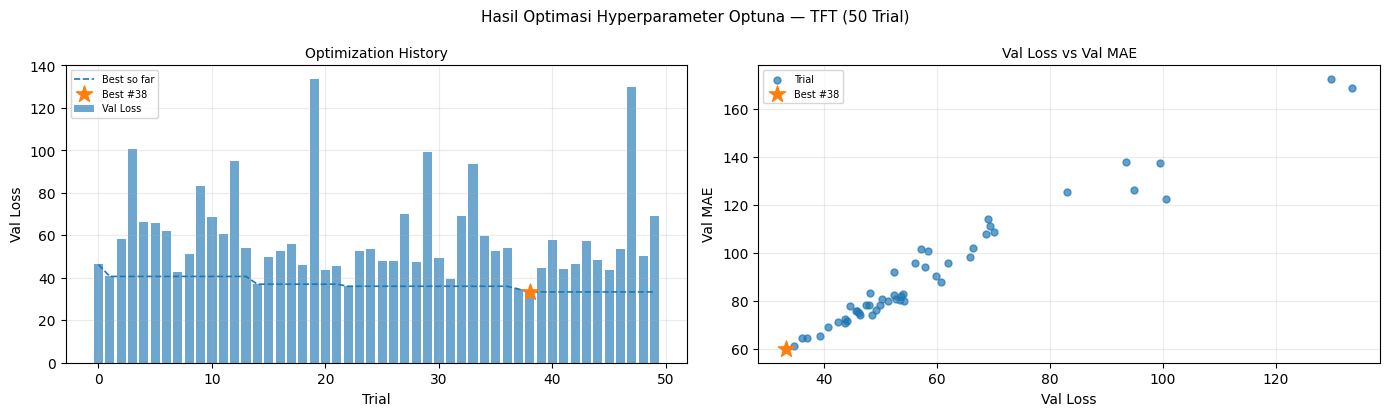


RINGKASAN OPTIMASI OPTUNA TFT
Combo ID          : 8
Learning rate     : 0.0005
Batch size        : 32
Jumlah trial valid: 50
Trial terbaik     : #38
Best Val Loss     : 33.3435
Best Val MAE      : 59.7387
Grafik tersimpan  : /content/hasil_evaluasi_tft/optuna_tft_optimization.png


In [ ]:
# ============================================================
# VISUALISASI HASIL OPTIMASI HYPERPARAMETER OPTUNA — TFT
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# 1. MENGAMBIL HASIL TRIAL OPTUNA
# ------------------------------------------------------------

completed_trials = [
    t for t in study.trials
    if t.value is not None
    and np.isfinite(t.value)
    and "val_MAE" in t.user_attrs
    and np.isfinite(t.user_attrs["val_MAE"])
]

if not completed_trials:
    raise ValueError(
        "Tidak ditemukan trial Optuna dengan validation loss "
        "dan validation MAE yang valid."
    )

trial_numbers = [t.number for t in completed_trials]
val_losses = [float(t.value) for t in completed_trials]
val_maes = [float(t.user_attrs["val_MAE"]) for t in completed_trials]

# Trial terbaik berdasarkan validation loss terendah
best_trial = study.best_trial
best_number = best_trial.number
best_loss = float(best_trial.value)
best_mae = float(best_trial.user_attrs["val_MAE"])

# ------------------------------------------------------------
# 2. MENGHITUNG NILAI BEST SO FAR
# ------------------------------------------------------------

best_so_far = []
current_best = float("inf")

for trial in study.trials:
    if trial.value is not None and np.isfinite(trial.value):
        current_best = min(current_best, float(trial.value))
    best_so_far.append(
        current_best if np.isfinite(current_best) else np.nan
    )

# ------------------------------------------------------------
# 3. MEMBUAT DUA PANEL GRAFIK
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

fig.suptitle(
    f"Hasil Optimasi Hyperparameter Optuna — TFT "
    f"({N_TRIALS_OPTUNA} Trial)",
    fontsize=11
)

# ============================================================
# PANEL KIRI: OPTIMIZATION HISTORY
# ============================================================

ax = axes[0]

# Bar validation loss setiap trial
ax.bar(
    trial_numbers,
    val_losses,
    width=0.8,
    alpha=0.65,
    label="Val Loss"
)

# Garis nilai terbaik yang telah ditemukan hingga setiap trial
ax.plot(
    range(len(best_so_far)),
    best_so_far,
    linestyle="--",
    linewidth=1.2,
    label="Best so far"
)

# Penanda trial terbaik
ax.scatter(
    best_number,
    best_loss,
    marker="*",
    s=150,
    zorder=5,
    label=f"Best #{best_number}"
)

ax.set_title("Optimization History", fontsize=10)
ax.set_xlabel("Trial")
ax.set_ylabel("Val Loss")
ax.grid(True, alpha=0.25)
ax.legend(fontsize=7)

# ============================================================
# PANEL KANAN: VALIDATION LOSS VS VALIDATION MAE
# ============================================================

ax = axes[1]

ax.scatter(
    val_losses,
    val_maes,
    s=25,
    alpha=0.7,
    label="Trial"
)

# Penanda trial terbaik
ax.scatter(
    best_loss,
    best_mae,
    marker="*",
    s=150,
    zorder=5,
    label=f"Best #{best_number}"
)

ax.set_title("Val Loss vs Val MAE", fontsize=10)
ax.set_xlabel("Val Loss")
ax.set_ylabel("Val MAE")
ax.grid(True, alpha=0.25)
ax.legend(fontsize=7)

# ------------------------------------------------------------
# 4. MENYIMPAN DAN MENAMPILKAN GRAFIK
# ------------------------------------------------------------

plt.tight_layout()

# Menentukan direktori output
if Path("/content").exists():
    output_dir = Path("/content/hasil_evaluasi_tft")
elif Path("/kaggle/working").exists():
    output_dir = Path("/kaggle/working/hasil_evaluasi_tft")
else:
    output_dir = Path.cwd() / "hasil_evaluasi_tft"

output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "optuna_tft_optimization.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 5. RINGKASAN
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("RINGKASAN OPTIMASI OPTUNA TFT")
print("=" * 55)
print(f"Combo ID          : {COMBO_ID}")
print(f"Learning rate     : {LEARNING_RATE}")
print(f"Batch size        : {BATCH_SIZE}")
print(f"Jumlah trial valid: {len(completed_trials)}")
print(f"Trial terbaik     : #{best_number}")
print(f"Best Val Loss     : {best_loss:.4f}")
print(f"Best Val MAE      : {best_mae:.4f}")
print(f"Grafik tersimpan  : {output_path}")
print("=" * 55)

## 8. Final Training - TFT Model

Tahap ini dilakukan untuk melatih model Temporal Fusion Transformer (TFT) menggunakan konfigurasi hiperparameter terbaik yang diperoleh dari proses optimasi Optuna pada tahap sebelumnya. Konfigurasi tersebut mencakup `hidden_size`, `attention_head_size`, `dropout`, dan `hidden_continuous_size`, sedangkan `learning_rate` dan `batch_size` tetap mengikuti kombinasi eksperimen (`COMBO_ID`) yang sedang dijalankan.

Sebelum pelatihan dimulai, konfigurasi hiperparameter terbaik disimpan kembali ke dalam variabel `best_params`. Cache CUDA juga dibersihkan untuk membantu mengelola penggunaan memori GPU apabila perangkat tersebut digunakan.

Model TFT dibentuk menggunakan dataset pelatihan (`training`) dengan konfigurasi sebagai berikut:

- **`learning_rate`**: laju pembelajaran yang ditetapkan berdasarkan kombinasi eksperimen.
- **`hidden_size`**: ukuran representasi tersembunyi model berdasarkan hasil optimasi Optuna.
- **`attention_head_size`**: jumlah *attention heads* berdasarkan hasil optimasi Optuna.
- **`dropout`**: tingkat *dropout* berdasarkan hasil optimasi Optuna.
- **`hidden_continuous_size`**: ukuran representasi untuk variabel kontinu berdasarkan hasil optimasi Optuna.
- **`QuantileLoss`**: fungsi kerugian yang digunakan selama pelatihan model.
- **Adam**: optimizer yang digunakan untuk memperbarui parameter model.

Pelatihan dibatasi hingga maksimal 150 epoch. Untuk mengendalikan proses pelatihan, digunakan mekanisme *early stopping* dengan memantau `val_loss`, nilai `min_delta` sebesar \(10^{-4}\), dan `patience` sebesar 15 epoch. Dengan pengaturan tersebut, pelatihan dapat dihentikan apabila nilai *validation loss* tidak mengalami perbaikan yang memenuhi batas minimum selama periode kesabaran yang ditentukan.

Selain itu, `ModelCheckpoint` digunakan untuk menyimpan model dengan nilai `val_loss` terbaik selama pelatihan. Penggunaan `gradient_clip_val` sebesar 0,1 juga diterapkan untuk membatasi besarnya gradien selama proses optimasi.

Model kemudian dilatih menggunakan `train_dataloader` dan dievaluasi pada setiap epoch menggunakan `val_dataloader`. Hasil dari tahap ini adalah model TFT yang telah dilatih dengan konfigurasi hiperparameter terpilih dan checkpoint berdasarkan performa terbaik pada data validasi. Model tersebut selanjutnya dapat digunakan pada tahap evaluasi dan pengujian sesuai dengan rancangan penelitian.

In [9]:

# ==============================================================================
# 8. FINAL TRAINING - TFT MODEL
# ==============================================================================

# Memulai pelatihan model TFT menggunakan konfigurasi eksperimen dan
# hiperparameter terbaik yang diperoleh dari proses optimasi Optuna.
print(f"\n-> Melatih Model TFT Final | COMBO {COMBO_ID} | LR={LEARNING_RATE} | BS={BATCH_SIZE}...")

# Menyimpan hiperparameter terbaik dari hasil optimasi Optuna serta
# melengkapi konfigurasi dengan learning rate, batch size, dan COMBO_ID
# yang digunakan pada eksperimen ini.
best_params = study.best_params.copy()
best_params["learning_rate"] = LEARNING_RATE
best_params["batch_size"] = BATCH_SIZE
best_params["combo_id"] = COMBO_ID

# Membersihkan cache CUDA sebelum pelatihan untuk membantu pengelolaan
# penggunaan memori GPU.
torch.cuda.empty_cache()

# Membentuk model Temporal Fusion Transformer (TFT) menggunakan dataset
# pelatihan dan konfigurasi hiperparameter terbaik hasil optimasi Optuna.
# Learning rate dan batch size tetap mengikuti kombinasi eksperimen.
best_tft_model = TemporalFusionTransformer.from_dataset(
    training,
    learning_rate          = LEARNING_RATE,
    hidden_size            = best_params["hidden_size"],
    attention_head_size    = best_params["attention_head_size"],
    dropout                = best_params["dropout"],
    hidden_continuous_size = best_params["hidden_continuous_size"],
    loss=QuantileLoss(),
    optimizer="adam",
    reduce_on_plateau_patience=5,
    log_interval=10,
)

# Mengatur early stopping dengan memantau val_loss.
# Pelatihan dapat dihentikan apabila tidak terdapat perbaikan minimal
# sebesar 1e-4 selama 15 epoch berturut-turut.
early_stop_final = EarlyStopping(monitor="val_loss", min_delta=1e-4, patience=15, mode="min")

# Mengonfigurasi checkpoint untuk menyimpan satu model dengan nilai
# validation loss terendah selama proses pelatihan.
checkpoint_cb    = ModelCheckpoint(
    monitor="val_loss", mode="min", save_top_k=1,
)

# Menyiapkan trainer untuk pelatihan model dengan maksimal 150 epoch.
# Gradient clipping diterapkan untuk membatasi besarnya gradien,
# sedangkan callback digunakan untuk mengendalikan penghentian pelatihan
# dan penyimpanan checkpoint berdasarkan performa pada data validasi.
final_trainer = pl.Trainer(
    max_epochs=150,
    accelerator=HARDWARE_ACCELERATOR,
    devices=HARDWARE_DEVICES,
    enable_model_summary=True,
    gradient_clip_val=0.1,
    callbacks=[early_stop_final, checkpoint_cb],
)

# Melatih model menggunakan data training dan mengevaluasi performanya
# menggunakan data validation pada setiap epoch.
final_trainer.fit(best_tft_model, train_dataloaders=train_dataloader, val_dataloaders=val_dataloader)



-> Melatih Model TFT Final | COMBO 8 | LR=0.0005 | BS=32...


INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃    ┃ Name                               ┃ Type                            ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0  │ loss                               │ QuantileLoss                    │      0 │ train │     0 │
│ 1  │ logging_metrics                    │ ModuleList                      │      0 │ train │     0 │
│ 2  │ input_embeddings                   │ MultiEmbedding                  │    132 │ train │     0 │
│ 3  │ prescalers                         │ ModuleDict                      │  2.5 K │ train │     0 │
│ 4  │ static_variable_selection          │ VariableSelectionNetwork        │ 34.6 K │ train │     0 │
│ 5  │ encoder_variable_selection         │ VariableSelectionNetwork        │  460 K │ train │     0 │
│ 6  │ decoder_variable_selection         │ VariableSelectionNetwork        │ 35.9 K │ train │     0 │
│ 7  │ static_context_variable_selection  │ GatedResidualNetwork            │ 66.3 K │ train │     0 │
│ 8  │ static_context_initial_hidden_lstm │ GatedResidualNetwork            │ 66.3 K │ train │     0 │
│ 9  │ static_context_initial_cell_lstm   │ GatedResidualNetwork            │ 66.3 K │ train │     0 │
│ 10 │ static_context_enrichment          │ GatedResidualNetwork            │ 66.3 K │ train │     0 │
│ 11 │ lstm_encoder                       │ LSTM                            │  132 K │ train │     0 │
│ 12 │ lstm_decoder                       │ LSTM                            │  132 K │ train │     0 │
│ 13 │ post_lstm_gate_encoder             │ GatedLinearUnit                 │ 33.0 K │ train │     0 │
│ 14 │ post_lstm_add_norm_encoder         │ AddNorm                         │    256 │ train │     0 │
│ 15 │ static_enrichment                  │ GatedResidualNetwork            │ 82.7 K │ train │     0 │
│ 16 │ multihead_attn                     │ InterpretableMultiHeadAttention │ 65.9 K │ train │     0 │
│ 17 │ post_attn_gate_norm                │ GateAddNorm                     │ 33.3 K │ train │     0 │
│ 18 │ pos_wise_ff                        │ GatedResidualNetwork            │ 66.3 K │ train │     0 │
│ 19 │ pre_output_gate_norm               │ GateAddNorm                     │ 33.3 K │ train │     0 │
│ 20 │ output_layer                       │ Linear                          │    903 │ train │     0 │
└────┴────────────────────────────────────┴─────────────────────────────────┴────────┴───────┴───────┘

Trainable params: 1.4 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 1.4 M                                                                                                
Total estimated model params size (MB): 5.502                                                                      
Modules in train mode: 805                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

## 9. Loading Best TFT Model

Tahap ini dilakukan untuk memuat kembali model Temporal Fusion Transformer (TFT) yang memiliki nilai *validation loss* terbaik selama proses pelatihan akhir. Lokasi berkas model diperoleh dari `best_model_path` pada callback `ModelCheckpoint`.

Sebelum model dimuat, fungsi `torch.load` disesuaikan melalui mekanisme *patching* agar parameter `weights_only=False` diterapkan secara eksplisit. Penyesuaian ini digunakan untuk mendukung proses pemuatan checkpoint yang menyimpan informasi model selain bobotnya.

Model kemudian dimuat menggunakan `TemporalFusionTransformer.load_from_checkpoint()` berdasarkan lokasi checkpoint terbaik. Model hasil pemuatan disimpan dalam variabel `best_tft` dan siap digunakan pada tahap evaluasi serta pengujian berikutnya.

In [ ]:
# ==============================================================================
# 9. Loading Best TFT MODEL
# ==============================================================================
# Mengambil lokasi checkpoint model dengan nilai validation loss terbaik
# berdasarkan hasil pelatihan akhir.
best_model_path = final_trainer.checkpoint_callback.best_model_path

# Menyimpan referensi fungsi torch.load asli sebelum dilakukan penyesuaian.
_orig = torch.load

# Menyesuaikan pemanggilan torch.load agar parameter weights_only=False
# diterapkan secara eksplisit saat memuat checkpoint.
def _patched(f, map_location=None, **kwargs):
    kwargs['weights_only'] = False
    return _orig(f, map_location=map_location, **kwargs)

# Memuat kembali model TFT dari checkpoint terbaik menggunakan fungsi
# torch.load yang telah disesuaikan.
with patch('torch.load', _patched):
    best_tft = TemporalFusionTransformer.load_from_checkpoint(best_model_path)

# Menampilkan lokasi checkpoint model TFT yang berhasil dimuat.
print(f"✅ Best TFT model loaded from: {best_model_path}")

✅ Best TFT model loaded from: /content/lightning_logs/version_0/checkpoints/epoch=2-step=324.ckpt


## 10. Evaluasi Model TFT

Tahap ini dilakukan untuk mengevaluasi performa model Temporal Fusion Transformer (TFT) pada data validasi menggunakan proses *forward pass* secara langsung pada GPU atau CPU, sesuai dengan ketersediaan perangkat komputasi. Model TFT terbaik yang telah dimuat pada tahap sebelumnya dipindahkan ke perangkat evaluasi dan diatur ke mode evaluasi.

Proses evaluasi dilakukan dengan menjalankan model pada setiap batch dari `val_eval_dataloader`. Untuk mengurangi penggunaan memori dan mempercepat komputasi, proses inferensi menggunakan `torch.inference_mode()`. Data masukan dipindahkan ke perangkat evaluasi, kemudian model menghasilkan prediksi melalui proses *forward pass*. Hasil keluaran model dikonversi menjadi prediksi menggunakan `to_prediction()`.

Prediksi dan nilai aktual dikumpulkan dari seluruh batch, kemudian dikonversi menjadi format NumPy untuk perhitungan metrik evaluasi. Panjang horizon prediksi setiap sampel diperhitungkan menggunakan `decoder_lengths`, sehingga hanya posisi prediksi yang valid yang disertakan dalam perhitungan. Pasangan nilai aktual dan prediksi yang tidak valid atau mengandung nilai non-finite juga dikeluarkan dari evaluasi.

Evaluasi dilakukan dengan membandingkan nilai aktual dan hasil prediksi menggunakan empat metrik berikut:

- **Mean Absolute Error (MAE):** mengukur rata-rata nilai absolut selisih antara harga aktual dan harga prediksi. Nilai yang lebih rendah menunjukkan kesalahan prediksi yang lebih kecil.
- **Root Mean Squared Error (RMSE):** mengukur akar dari rata-rata kuadrat kesalahan prediksi. Metrik ini memberikan penalti lebih besar terhadap kesalahan yang bernilai besar.
- **Mean Absolute Percentage Error (MAPE):** mengukur rata-rata kesalahan absolut dalam bentuk persentase terhadap nilai aktual, dengan penambahan konstanta kecil untuk menghindari pembagian dengan nol.
- **Coefficient of Determination (R²):** mengukur kemampuan model dalam menjelaskan variasi nilai aktual berdasarkan hasil prediksi. Nilainya dapat digunakan untuk menilai kesesuaian prediksi terhadap data aktual.

Hasil evaluasi menampilkan perangkat komputasi yang digunakan, dimensi matriks prediksi, jumlah pasangan aktual-prediksi yang valid, serta nilai MAE, RMSE, MAPE, dan R². Keempat metrik tersebut digunakan untuk mengukur performa model TFT pada data validasi dalam konteks prediksi harga emas.

In [ ]:

# ==============================================================================
# 10. EVALUASI Model Temporal Fusion Transformer (TFT)  
# ==============================================================================

# Memulai evaluasi model TFT pada data validasi.
print("\n-> Evaluasi TFT Model...")

# Menentukan perangkat evaluasi berdasarkan ketersediaan GPU.
# Jika GPU tidak tersedia, proses evaluasi dijalankan menggunakan CPU.
evaluation_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
best_tft = best_tft.to(evaluation_device)
best_tft.eval()


# Memindahkan tensor di dalam struktur data dict, list, atau tuple
# ke perangkat komputasi yang ditentukan secara rekursif.
def move_to_device(data, target_device):
    """Memindahkan tensor di dalam dict/list/tuple ke device yang dipilih."""
    if torch.is_tensor(data):
        return data.to(target_device)
    if isinstance(data, dict):
        return {key: move_to_device(value, target_device) for key, value in data.items()}
    if isinstance(data, list):
        return [move_to_device(value, target_device) for value in data]
    if isinstance(data, tuple):
        return tuple(move_to_device(value, target_device) for value in data)
    return data


# Menyiapkan penampung untuk prediksi, nilai aktual, dan panjang horizon
# prediksi dari setiap batch data validasi.
tft_prediction_batches = []
tft_actual_batches = []
tft_decoder_length_batches = []

# Menjalankan inferensi tanpa menghitung gradien untuk mengurangi
# penggunaan memori dan kebutuhan komputasi selama evaluasi.
with torch.inference_mode():
    for x_batch, y_batch in val_eval_dataloader:
        # Memindahkan data masukan ke perangkat evaluasi yang digunakan.
        x_device = move_to_device(x_batch, evaluation_device)

        # Melakukan forward pass menggunakan model TFT untuk memperoleh
        # keluaran prediksi pada batch saat ini.
        raw_batch_output = best_tft(x_device)
        batch_prediction = best_tft.to_prediction(raw_batch_output)

        # Menyesuaikan format keluaran agar diperoleh tensor prediksi
        # yang dapat digunakan dalam proses evaluasi.
        if isinstance(batch_prediction, (list, tuple)):
            batch_prediction = batch_prediction[0]
        if hasattr(batch_prediction, "output"):
            batch_prediction = batch_prediction.output

        # Mengambil nilai aktual dari batch target.
        batch_actual = y_batch[0] if isinstance(y_batch, (list, tuple)) else y_batch
        if isinstance(batch_actual, (list, tuple)):
            batch_actual = batch_actual[0]

        # Memindahkan prediksi dan nilai aktual ke CPU agar dapat
        # dikonversi ke NumPy untuk perhitungan metrik evaluasi.
        batch_prediction = batch_prediction.detach().cpu()
        batch_actual = batch_actual.detach().cpu()

        # Memastikan tensor prediksi dan aktual memiliki dimensi
        # yang sesuai untuk penggabungan antarbatch.
        if batch_prediction.ndim == 1:
            batch_prediction = batch_prediction.unsqueeze(0)
        if batch_actual.ndim == 1:
            batch_actual = batch_actual.unsqueeze(0)

        # Menyimpan prediksi, nilai aktual, dan panjang decoder
        # untuk setiap batch yang telah diproses.
        tft_prediction_batches.append(batch_prediction)
        tft_actual_batches.append(batch_actual)
        tft_decoder_length_batches.append(x_batch["decoder_lengths"].detach().cpu())

# Memastikan proses evaluasi menghasilkan setidaknya satu batch.
if not tft_prediction_batches:
    raise ValueError("Validation dataloader tidak menghasilkan batch evaluasi.")

# Menggabungkan seluruh batch menjadi matriks prediksi, aktual,
# dan panjang decoder, kemudian mengonversinya ke format NumPy.
tft_prediction_matrix = torch.cat(tft_prediction_batches, dim=0).numpy()
tft_actual_matrix = torch.cat(tft_actual_batches, dim=0).numpy()
tft_decoder_lengths = torch.cat(tft_decoder_length_batches, dim=0).numpy()

# Memastikan dimensi matriks prediksi dan nilai aktual sama
# sebelum dilakukan perhitungan metrik evaluasi.
if tft_prediction_matrix.shape != tft_actual_matrix.shape:
    raise ValueError(
        f"Bentuk aktual {tft_actual_matrix.shape} dan prediksi "
        f"{tft_prediction_matrix.shape} tidak sama."
    )

# Membentuk indeks posisi horizon prediksi dan menentukan posisi
# yang masih berada dalam panjang decoder valid setiap sampel.
horizon_positions = np.arange(tft_prediction_matrix.shape[1])[None, :]
valid_length_mask = horizon_positions < tft_decoder_lengths[:, None]

# Mengidentifikasi pasangan nilai aktual dan prediksi yang bernilai
# finite, kemudian menggabungkannya dengan mask panjang decoder
# untuk memperoleh pasangan data yang valid.
finite_mask = np.isfinite(tft_actual_matrix) & np.isfinite(tft_prediction_matrix)
overall_valid_mask = valid_length_mask & finite_mask

# Mengambil nilai aktual dan prediksi hanya pada posisi yang valid
# untuk digunakan dalam perhitungan metrik evaluasi.
flat_actual_clean = tft_actual_matrix[overall_valid_mask]
flat_pred_clean = tft_prediction_matrix[overall_valid_mask]

# Memastikan tersedia pasangan aktual-prediksi yang valid
# sebelum menghitung metrik evaluasi.
if len(flat_actual_clean) == 0:
    raise ValueError("Tidak ada pasangan aktual-prediksi valid untuk evaluasi.")

# Menghitung MAE untuk mengukur rata-rata kesalahan absolut
# antara nilai aktual dan hasil prediksi.
mae_tft = mean_absolute_error(flat_actual_clean, flat_pred_clean)

# Menghitung RMSE untuk mengukur besarnya kesalahan prediksi
# dengan memberikan penalti lebih besar pada kesalahan kuadrat.
rmse_tft = np.sqrt(mean_squared_error(flat_actual_clean, flat_pred_clean))

# Menghitung MAPE dalam persentase dengan menambahkan konstanta kecil
# pada penyebut untuk menghindari pembagian dengan nol.
mape_tft = np.mean(
    np.abs((flat_actual_clean - flat_pred_clean) / (np.abs(flat_actual_clean) + 1e-8))
) * 100

# Menghitung R² untuk mengukur kesesuaian hasil prediksi
# terhadap variasi nilai aktual.
r2_tft = r2_score(flat_actual_clean, flat_pred_clean)

# Menampilkan perangkat evaluasi, dimensi matriks prediksi,
# jumlah pasangan data valid, dan hasil seluruh metrik evaluasi.
print(f"Perangkat evaluasi : {evaluation_device}")
print(f"Bentuk matriks      : {tft_prediction_matrix.shape} [sampel, horizon]")
print(f"\n{'=' * 60}")
print(" HASIL EVALUASI KESELURUHAN - TFT")
print(f"{'=' * 60}")
print(f" Jumlah pasangan : {len(flat_actual_clean):>10,}")
print(f" MAE             : {mae_tft:>10,.4f}")
print(f" RMSE            : {rmse_tft:>10,.4f}")
print(f" MAPE            : {mape_tft:>8.2f} %")
print(f" R²              : {r2_tft:>8.4f}")
print(f"{'=' * 60}")



-> Evaluasi TFT Model...
Perangkat evaluasi : cuda
Bentuk matriks      : (894, 7) [sampel, horizon]

 HASIL EVALUASI KESELURUHAN - TFT
 Jumlah pasangan :      6,258
 MAE             :    68.5037
 RMSE            :   107.6815
 MAPE            :     1.97 %
 R²              :   0.9884


## 11. Evaluasi Multi-Horizon TFT (H+1 sampai H+7)

Evaluasi ini mengukur performa model TFT berdasarkan jarak prediksi, mulai dari H+1 (satu hari ke depan) hingga H+7 (tujuh hari ke depan). Setiap horizon dievaluasi menggunakan pasangan nilai aktual dan prediksi pada posisi yang sama.

Performa model diukur menggunakan MAE, RMSE, MAPE, dan R². Nilai MAE, RMSE, dan MAPE yang lebih rendah menunjukkan kesalahan prediksi yang lebih kecil, sedangkan R² yang mendekati 1 menunjukkan kesesuaian prediksi yang lebih baik. Hasil disajikan dalam tabel dan grafik untuk membandingkan performa model pada setiap horizon.


-> Menghitung evaluasi TFT untuk setiap horizon...

 HASIL EVALUASI MULTI-HORIZON TFT
Horizon  Hari_ke  Jumlah_Sampel     MAE     RMSE MAPE_Persen     R2
    H+1        1            894 45.3829  72.1522        1.28 0.9948
    H+2        2            894 55.3592  86.8816        1.58 0.9925
    H+3        3            894 62.3997  97.1418        1.79 0.9905
    H+4        4            894 69.7944 107.9386        2.01 0.9883
    H+5        5            894 76.7027 117.0824        2.21 0.9863
    H+6        6            894 82.6727 125.9004        2.39 0.9842
    H+7        7            894 87.2141 133.2902        2.53 0.9822


,Horizon,Hari_ke,Jumlah_Sampel,MAE,RMSE,MAPE_Persen,R2
0,H+1,1,894,45.3829,72.1522,1.28%,0.9948
1,H+2,2,894,55.3592,86.8816,1.58%,0.9925
2,H+3,3,894,62.3997,97.1418,1.79%,0.9905
3,H+4,4,894,69.7944,107.9386,2.01%,0.9883
4,H+5,5,894,76.7027,117.0824,2.21%,0.9863
5,H+6,6,894,82.6727,125.9004,2.39%,0.9842
6,H+7,7,894,87.2141,133.2902,2.53%,0.9822


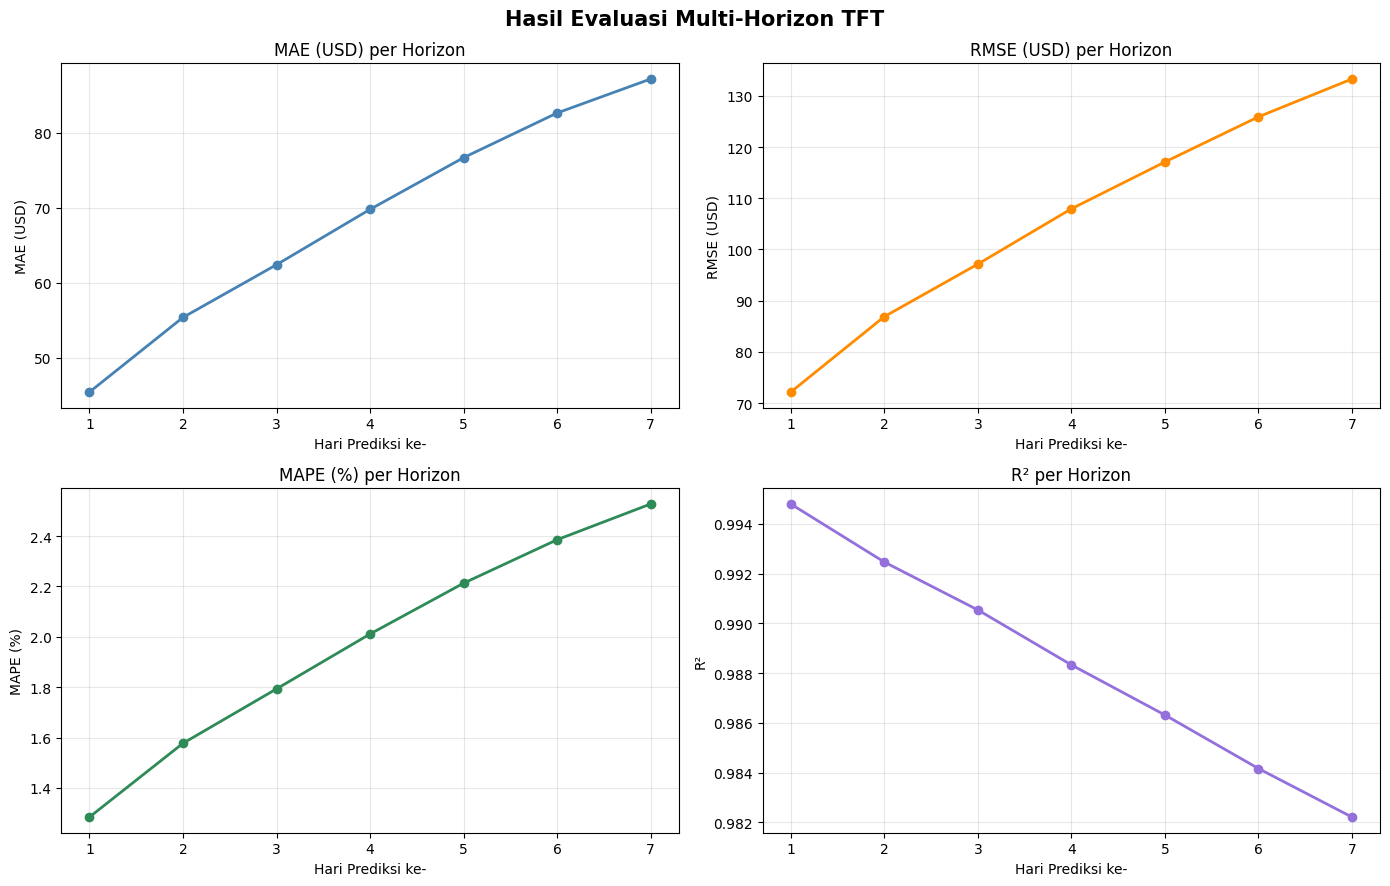


✅ Tabel disimpan : /content/hasil_evaluasi_tft/hasil_evaluasi_multi_horizon_tft.csv
✅ Grafik disimpan: /content/hasil_evaluasi_tft/grafik_evaluasi_multi_horizon_tft.png


In [12]:

# ==============================================================================
# 11. HASIL EVALUASI MULTI-HORIZON TFT (H+1 SAMPAI H+7)
# ==============================================================================

from pathlib import Path

# Menghitung metrik evaluasi model TFT untuk setiap horizon prediksi.
print("\n-> Menghitung evaluasi TFT untuk setiap horizon...")

# Menyiapkan penampung hasil evaluasi setiap horizon.
# Jumlah horizon disesuaikan dengan panjang prediksi yang ditentukan
# dan jumlah horizon yang tersedia pada matriks prediksi.
multi_horizon_rows = []
available_horizons = min(max_prediction_length, tft_prediction_matrix.shape[1])

# Mengevaluasi prediksi pada setiap horizon, mulai dari H+1 hingga H+7.
for horizon_index in range(available_horizons):
    # Memilih sampel dengan panjang decoder yang mencakup horizon saat ini
    # serta nilai aktual dan prediksi yang valid.
    horizon_mask = (
        (tft_decoder_lengths > horizon_index)
        & np.isfinite(tft_actual_matrix[:, horizon_index])
        & np.isfinite(tft_prediction_matrix[:, horizon_index])
    )

    # Mengambil pasangan nilai aktual dan prediksi pada horizon yang sama.
    actual_h = tft_actual_matrix[horizon_mask, horizon_index]
    prediction_h = tft_prediction_matrix[horizon_mask, horizon_index]

    # Melewati horizon apabila tidak terdapat pasangan data yang valid.
    if len(actual_h) == 0:
        continue

    # Menghitung MAE, RMSE, dan MAPE untuk mengukur kesalahan prediksi
    # pada horizon yang sedang dievaluasi.
    mae_h = mean_absolute_error(actual_h, prediction_h)
    rmse_h = np.sqrt(mean_squared_error(actual_h, prediction_h))
    mape_h = np.mean(
        np.abs((actual_h - prediction_h) / (np.abs(actual_h) + 1e-8))
    ) * 100

    # Menghitung R² apabila jumlah sampel minimal dua dan nilai aktual
    # memiliki variasi yang memadai. Jika tidak, R² ditetapkan sebagai NaN.
    if len(actual_h) >= 2 and not np.allclose(actual_h, actual_h[0]):
        r2_h = r2_score(actual_h, prediction_h)
    else:
        r2_h = np.nan

    # Menyimpan horizon, jumlah sampel, dan hasil metrik evaluasi
    # ke dalam struktur data untuk disusun menjadi tabel.
    multi_horizon_rows.append({
        "Horizon": f"H+{horizon_index + 1}",
        "Hari_ke": horizon_index + 1,
        "Jumlah_Sampel": int(len(actual_h)),
        "MAE": float(mae_h),
        "RMSE": float(rmse_h),
        "MAPE_Persen": float(mape_h),
        "R2": float(r2_h) if np.isfinite(r2_h) else np.nan,
    })

# Mengubah hasil evaluasi seluruh horizon menjadi DataFrame.
multi_horizon_results = pd.DataFrame(multi_horizon_rows)

# Menghentikan proses apabila tidak ada hasil evaluasi yang dapat ditampilkan.
if multi_horizon_results.empty:
    raise ValueError("Hasil evaluasi multi-horizon kosong.")

# Menampilkan tabel hasil evaluasi dengan format angka yang konsisten.
print(f"\n{'=' * 94}")
print(" HASIL EVALUASI MULTI-HORIZON TFT")
print(f"{'=' * 94}")
print(
    multi_horizon_results.to_string(
        index=False,
        formatters={
            "MAE": "{:,.4f}".format,
            "RMSE": "{:,.4f}".format,
            "MAPE_Persen": "{:,.2f}".format,
            "R2": lambda value: "-" if pd.isna(value) else f"{value:,.4f}",
        },
    )
)
print(f"{'=' * 94}")

# Menampilkan tabel evaluasi dengan gradasi warna untuk membantu
# membandingkan nilai kesalahan dan R² antarhorizon.
display(
    multi_horizon_results.style
    .format({
        "MAE": "{:,.4f}",
        "RMSE": "{:,.4f}",
        "MAPE_Persen": "{:,.2f}%",
        "R2": "{:,.4f}",
    })
    .background_gradient(subset=["MAE", "RMSE", "MAPE_Persen"], cmap="YlOrRd")
    .background_gradient(subset=["R2"], cmap="RdYlGn")
)

# Membuat empat grafik untuk menunjukkan perubahan MAE, RMSE, MAPE,
# dan R² berdasarkan jarak horizon prediksi.
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plot_specs = [
    ("MAE", "MAE (USD)", "steelblue"),
    ("RMSE", "RMSE (USD)", "darkorange"),
    ("MAPE_Persen", "MAPE (%)", "seagreen"),
    ("R2", "R²", "mediumpurple"),
]

# Menggambar setiap metrik terhadap hari prediksi ke-.
for axis, (column, label, color) in zip(axes.flat, plot_specs):
    axis.plot(
        multi_horizon_results["Hari_ke"],
        multi_horizon_results[column],
        marker="o",
        linewidth=2,
        color=color,
    )
    axis.set_title(f"{label} per Horizon")
    axis.set_xlabel("Hari Prediksi ke-")
    axis.set_ylabel(label)
    axis.set_xticks(multi_horizon_results["Hari_ke"])
    axis.grid(alpha=0.3)

# Menambahkan judul utama dan merapikan tata letak grafik.
plt.suptitle("Hasil Evaluasi Multi-Horizon TFT", fontsize=15, fontweight="bold")
plt.tight_layout()

# Menentukan direktori penyimpanan berdasarkan lingkungan komputasi
# yang tersedia, dengan direktori kerja sebagai alternatif.
if Path("/content").exists():
    multi_output_dir = Path("/content/hasil_evaluasi_tft")
elif Path("/kaggle/working").exists():
    multi_output_dir = Path("/kaggle/working/hasil_evaluasi_tft")
else:
    multi_output_dir = Path.cwd() / "hasil_evaluasi_tft"

# Membuat direktori penyimpanan jika belum tersedia dan menetapkan
# nama berkas untuk tabel evaluasi serta grafik.
multi_output_dir.mkdir(parents=True, exist_ok=True)
multi_csv_path = multi_output_dir / "hasil_evaluasi_multi_horizon_tft.csv"
multi_plot_path = multi_output_dir / "grafik_evaluasi_multi_horizon_tft.png"

# Menyimpan hasil evaluasi ke format CSV dan grafik ke format PNG.
multi_horizon_results.to_csv(multi_csv_path, index=False)
plt.savefig(multi_plot_path, dpi=150, bbox_inches="tight")
plt.show()

# Menampilkan lokasi penyimpanan berkas hasil evaluasi.
print(f"\n✅ Tabel disimpan : {multi_csv_path}")
print(f"✅ Grafik disimpan: {multi_plot_path}")


## 12. Interpretabilitas Model TFT

Tahap ini menganalisis interpretabilitas model Temporal Fusion Transformer (TFT) menggunakan data validasi. Model menghasilkan keluaran interpretasi melalui `interpret_output()` dengan metode reduksi *sum*, kemudian divisualisasikan menggunakan `plot_interpretation()`. Hasil visualisasi digunakan untuk memahami pengaruh variabel dalam proses prediksi model TFT.


-> Interpretability TFT...


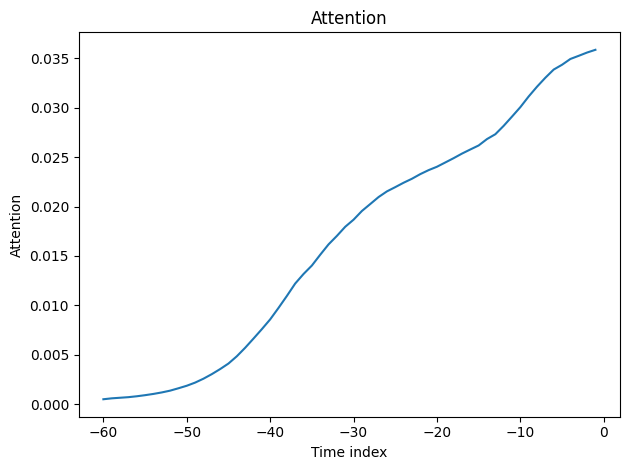

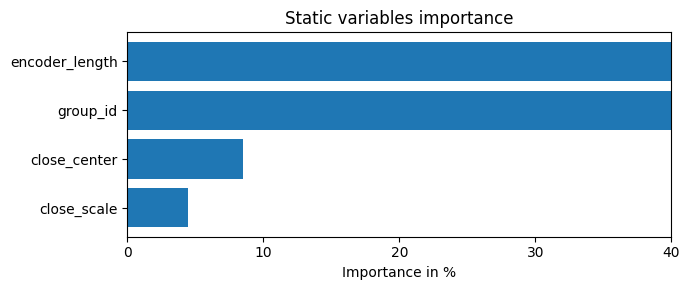

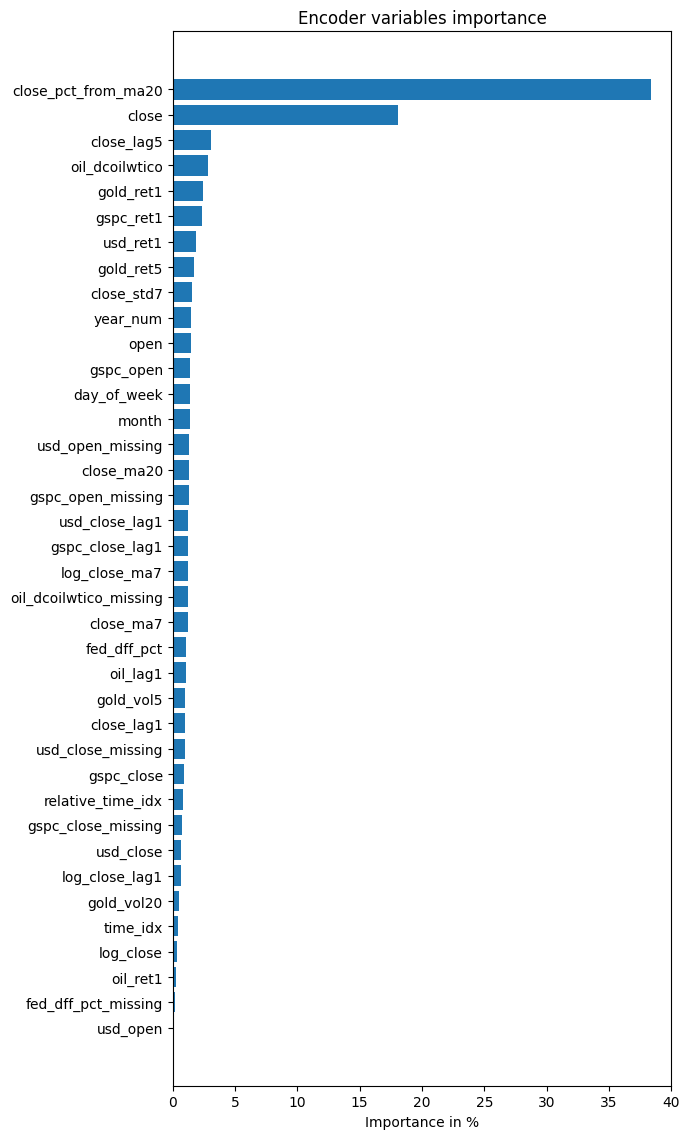

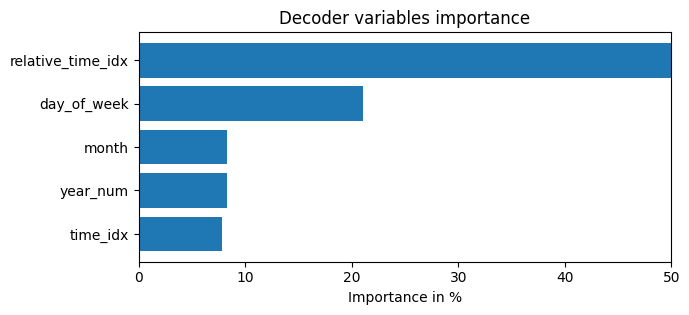

Model device: cpu
Interpretability TFT berhasil dijalankan.


In [ ]:
# ==============================================================================
# 12. INTERPRETABILITY - TFT
# ==============================================================================

# Menampilkan informasi bahwa proses interpretabilitas TFT dimulai.
print("\n-> Interpretability TFT...")

# Mengambil satu batch data dari validation dataloader untuk interpretabilitas.
interpretation_batch = next(iter(val_eval_dataloader), None)

# Menghentikan proses jika dataloader validasi tidak menyediakan data.
if interpretation_batch is None:
    raise ValueError("Validation dataloader kosong untuk interpretability.")

# Memisahkan data input dari batch validasi.
x_interpretation, _ = interpretation_batch

# Mengidentifikasi perangkat komputasi yang digunakan model TFT.
model_device = next(best_tft.parameters()).device

# Mengatur model ke mode evaluasi.
best_tft.eval()

# Memindahkan data input ke perangkat komputasi yang sama dengan model.
x_interpretation = move_to_device(x_interpretation, model_device)

# Menjalankan inferensi tanpa menghitung gradien.
with torch.inference_mode():
    raw_interpretation_output = best_tft(x_interpretation)

# Menghasilkan informasi interpretasi dari keluaran model.
# Reduksi sum digunakan untuk mengakumulasi nilai interpretasi.
interpretation = best_tft.interpret_output(
    raw_interpretation_output,
    reduction="sum",
)

# Memvisualisasikan hasil interpretasi model TFT.
interpretation_figures = best_tft.plot_interpretation(interpretation)

# Memastikan keluaran interpretasi berupa dictionary.
if isinstance(interpretation_figures, dict):

    # Menyimpan nama grafik yang sudah ditampilkan agar tidak double.
    displayed_figures = set()

    # Memproses setiap grafik interpretabilitas.
    for figure_name, figure in interpretation_figures.items():

        # Mengidentifikasi jenis grafik berdasarkan nama figure.
        figure_name_lower = figure_name.lower()

        # Mencegah figure yang sama ditampilkan lebih dari satu kali.
        if figure_name_lower in displayed_figures:
            plt.close(figure)
            continue

        displayed_figures.add(figure_name_lower)

        # Mengatur grafik Encoder Variables.
        if "encoder" in figure_name_lower:
            for ax in figure.axes:
                ax.set_xlim(0, 40)
                ax.set_xticks(range(0, 41, 5))

        # Mengatur grafik Decoder Variables.
        elif "decoder" in figure_name_lower:
            for ax in figure.axes:
                ax.set_xlim(0, 50)
                ax.set_xticks(range(0, 51, 10))

        # Mengatur grafik Static Variables.
        elif "static" in figure_name_lower:
            for ax in figure.axes:
                ax.set_xlim(0, 40)
                ax.set_xticks(range(0, 41, 10))

        # Menyimpan setiap grafik interpretabilitas satu kali.
        figure.tight_layout()
        figure.savefig(
            f"tft_interpretability_{figure_name}.png",
            dpi=150,
            bbox_inches="tight",
        )

        # Menampilkan setiap figure satu kali.
        display(figure)

        # Menutup figure setelah ditampilkan agar tidak muncul ulang
        # secara otomatis pada akhir eksekusi cell.
        plt.close(figure)

else:
    # Menghentikan proses jika format keluaran berbeda dari yang diharapkan.
    raise TypeError(
        "Format keluaran plot_interpretation() tidak sesuai asumsi. "
        "Periksa tipe dan struktur nilai yang dikembalikan."
    )

# Menampilkan perangkat komputasi yang digunakan model.
print(f"Model device: {model_device}")

# Mengonfirmasi bahwa proses interpretabilitas selesai dijalankan.
print("Interpretability TFT berhasil dijalankan.")

## 13. Prediksi Harga Emas untuk Tujuh Hari ke Depan

Pada tahap ini, model Temporal Fusion Transformer (TFT) digunakan untuk memprediksi harga emas selama tujuh hari kerja berikutnya berdasarkan pola historis dan variabel yang digunakan dalam penelitian. Data historis pada periode terakhir digunakan sebagai masukan model untuk menghasilkan estimasi harga pada setiap horizon prediksi.

Hasil prediksi kemudian dibandingkan dengan harga penutupan terakhir untuk mengidentifikasi perubahan harga yang diperkirakan terjadi selama periode tersebut. Selanjutnya, visualisasi disusun dengan menggabungkan data historis harga penutupan selama 90 hari terakhir dan hasil prediksi tujuh hari ke depan. Penyajian ini bertujuan untuk memperlihatkan kesinambungan pola harga historis dengan estimasi harga pada periode prediksi.

Visualisasi tersebut digunakan untuk mengamati arah pergerakan harga yang diprediksi oleh model TFT. Hasil prediksi merupakan estimasi berdasarkan pola yang dipelajari selama pelatihan dan tidak merepresentasikan kepastian pergerakan harga emas di masa mendatang.

In [ ]:
# ==============================================================================
# 13. PREDIKSI 7 HARI KE DEPAN
# ==============================================================================

# Menampilkan informasi awal proses prediksi berdasarkan data terakhir.
print("\n-> Prediksi 7 hari ke depan dari data terakhir...")

# Mengambil data historis terakhir sesuai panjang encoder model.
last_data = df.tail(max_encoder_length).copy()

# Menentukan tanggal terakhir yang tersedia dalam dataset.
last_date = df["date"].max()

# Membentuk tujuh tanggal prediksi pada hari kerja setelah tanggal terakhir.
future_dates = pd.bdate_range(
    last_date + pd.Timedelta(days=1),
    periods=max_prediction_length
)

# Membuat DataFrame untuk menampung data periode prediksi.
future_df = pd.DataFrame({"date": future_dates})

# Menambahkan identitas deret waktu dan fitur kalender untuk periode prediksi.
future_df["group_id"] = "XAU_USD"
future_df["day_of_week"] = future_df["date"].dt.day_name().astype(str)
future_df["month"] = future_df["date"].dt.month.astype(str)
future_df["year_num"] = (future_df["date"].dt.year - 2021).astype(float)

# Membuat indeks waktu berurutan setelah indeks terakhir pada data historis.
future_df["time_idx"] = list(
    range(
        int(df["time_idx"].max()) + 1,
        int(df["time_idx"].max()) + 1 + max_prediction_length
    )
)

# Melengkapi kolom yang belum tersedia menggunakan nilai terakhir pada dataset.
for col in df.columns:
    if col not in future_df.columns:
        future_df[col] = df[col].iloc[-1]

# Mengisi variabel real yang tidak diketahui untuk periode prediksi
# menggunakan nilai terakhir yang tersedia.
for col in unknown_reals:
    future_df[col] = df[col].iloc[-1]

# Menggunakan harga penutupan terakhir sebagai nilai awal kolom target.
future_df["close"] = df["close"].iloc[-1]

# Menggabungkan data historis dan data masa depan untuk membentuk urutan prediksi.
predict_df = pd.concat([last_data, future_df], ignore_index=True)

# Membentuk dataset prediksi berdasarkan konfigurasi dataset pelatihan.
predict_dataset = TimeSeriesDataSet.from_dataset(
    training,
    predict_df,
    predict=True,
    stop_randomization=True
)

# Membuat dataloader untuk memproses data prediksi dengan batch berukuran satu.
predict_loader = predict_dataset.to_dataloader(
    train=False,
    batch_size=1,
    num_workers=0
)

# Mengambil batch pertama dari dataloader prediksi.
future_batch = next(iter(predict_loader), None)

# Menghentikan proses jika urutan data prediksi tidak berhasil dibentuk.
if future_batch is None:
    raise ValueError("Predict loader kosong. Sequence prediksi tidak terbentuk.")

# Mengambil input model dari batch prediksi.
x_future, _ = future_batch

# Mengidentifikasi perangkat komputasi dan mengatur model ke mode evaluasi.
model_device = next(best_tft.parameters()).device
best_tft.eval()

# Memindahkan input prediksi ke perangkat komputasi yang digunakan model.
x_future = move_to_device(x_future, model_device)

# Menghasilkan prediksi tanpa menghitung gradien.
with torch.inference_mode():
    raw_future_output = best_tft(x_future)
    future_prediction_tensor = best_tft.to_prediction(raw_future_output)

# Mengambil elemen pertama jika hasil prediksi berbentuk list atau tuple.
if isinstance(future_prediction_tensor, (list, tuple)):
    future_prediction_tensor = future_prediction_tensor[0]

# Mengambil tensor output jika hasil prediksi memiliki atribut output.
if hasattr(future_prediction_tensor, "output"):
    future_prediction_tensor = future_prediction_tensor.output

# Mengubah hasil prediksi menjadi daftar nilai numerik pada CPU.
future_values = (
    future_prediction_tensor[0]
    .detach()
    .cpu()
    .reshape(-1)
    .numpy()
    .tolist()
)

# Menentukan nama file yang digunakan untuk membaca data aktual.
actual_file_path = "aktual.csv"

# Membaca data aktual dari file CSV.
actual_df = pd.read_csv(actual_file_path)

# Memastikan kolom tanggal dan harga aktual tersedia dalam file CSV.
required_columns = {"date", "actual"}
if not required_columns.issubset(actual_df.columns):
    raise ValueError(
        "CSV harus memiliki kolom 'date' dan 'actual'. "
        f"Kolom yang ditemukan: {actual_df.columns.tolist()}"
    )

# Mengonversi tanggal aktual menjadi format datetime.
actual_df["date"] = pd.to_datetime(
    actual_df["date"],
    errors="coerce"
).dt.normalize()

# Mengonversi harga aktual menjadi numerik.
actual_df["actual"] = pd.to_numeric(
    actual_df["actual"],
    errors="coerce"
)

# Menghapus baris yang memiliki tanggal atau harga aktual tidak valid.
actual_df = actual_df.dropna(subset=["date", "actual"])

# Memastikan setiap tanggal aktual hanya muncul satu kali.
if actual_df["date"].duplicated().any():
    raise ValueError("CSV aktual mengandung tanggal duplikat.")

# Membentuk pemetaan tanggal untuk memudahkan pencocokan harga aktual.
actual_lookup = actual_df.set_index("date")["actual"].to_dict()

# Menampilkan judul hasil perbandingan prediksi dan harga aktual.
print(f"\n{'=' * 85}")
print(" PERBANDINGAN PREDIKSI HARGA EMAS TFT DENGAN HARGA AKTUAL")
print(f"{'=' * 85}")

# Mengambil harga penutupan terakhir sebagai informasi referensi.
last_close = df["close"].iloc[-1]

# Menampilkan tanggal dan harga terakhir dari dataset.
print(f" Harga terakhir ({last_date.date()}): ${last_close:,.2f}")
print()

# Menampilkan judul kolom tabel perbandingan.
print(
    f" {'Tanggal':<15}"
    f" {'Prediksi TFT':>16}"
    f" {'Harga Aktual':>18}"
    f" {'Error Absolut':>18}"
)
print(f" {'-' * 70}")

# Menyiapkan data untuk menyimpan hasil perbandingan prediksi dan aktual.
comparison_rows = []

# Mencocokkan setiap tanggal prediksi dengan tanggal pada data aktual.
for d, p in zip(future_dates, future_values):

    # Mengubah tanggal prediksi ke format datetime untuk pencocokan.
    prediction_date = pd.Timestamp(d).normalize()

    # Mengambil harga aktual berdasarkan tanggal prediksi.
    actual_price = actual_lookup.get(prediction_date, None)

    # Menghitung error absolut jika harga aktual tersedia.
    if actual_price is not None:
        absolute_error = abs(float(p) - float(actual_price))
        actual_display = f"${actual_price:,.2f}"
        error_display = f"${absolute_error:,.2f}"
    else:
        absolute_error = None
        actual_display = "-"
        error_display = "-"

    # Menyimpan hasil perbandingan untuk penghitungan metrik evaluasi.
    comparison_rows.append({
        "tanggal": prediction_date,
        "prediksi_tft": float(p),
        "aktual": actual_price,
        "error_absolut": absolute_error
    })

    # Menampilkan hasil prediksi, harga aktual, dan error untuk setiap tanggal.
    print(
        f" {str(prediction_date.date()):<15}"
        f" ${float(p):>14,.2f}"
        f" {actual_display:>18}"
        f" {error_display:>18}"
    )

# Menampilkan penutup tabel.
print(f"{'=' * 85}")

# Mengubah hasil perbandingan menjadi DataFrame.
comparison_df = pd.DataFrame(comparison_rows)

# Mengambil baris yang memiliki pasangan prediksi dan harga aktual.
valid_comparison = comparison_df.dropna(
    subset=["aktual", "error_absolut"]
)

# Menghitung MAE jika tersedia pasangan prediksi dan harga aktual.
if not valid_comparison.empty:
    mae = valid_comparison["error_absolut"].mean()

    print(f"Jumlah data yang berhasil dicocokkan: {len(valid_comparison)}")
    print(f"MAE perbandingan: ${mae:,.2f}")
else:
    print("Belum ada tanggal prediksi yang cocok dengan data aktual.")

# Menampilkan perangkat komputasi yang digunakan model.
print(f"Model device: {model_device}")


-> Prediksi 7 hari ke depan dari data terakhir...

 PERBANDINGAN PREDIKSI HARGA EMAS TFT DENGAN HARGA AKTUAL
 Harga terakhir (2026-10-12): $4,167.47

 Tanggal             Prediksi TFT       Harga Aktual      Error Absolut
 ----------------------------------------------------------------------
 2026-10-13      $      4,109.86          $4,157.95             $48.09
 2026-10-14      $      4,113.71          $4,105.70              $8.01
 2026-10-15      $      4,140.52          $4,170.87             $30.35
 2026-10-16      $      4,148.34          $4,165.50             $17.16
 2026-10-19      $      4,143.44          $4,140.87              $2.57
 2026-10-20      $      4,141.84          $4,124.94             $16.90
 2026-10-21      $      4,146.18          $4,140.97              $5.21
Jumlah data yang berhasil dicocokkan: 7
MAE perbandingan: $18.33
Model device: cpu


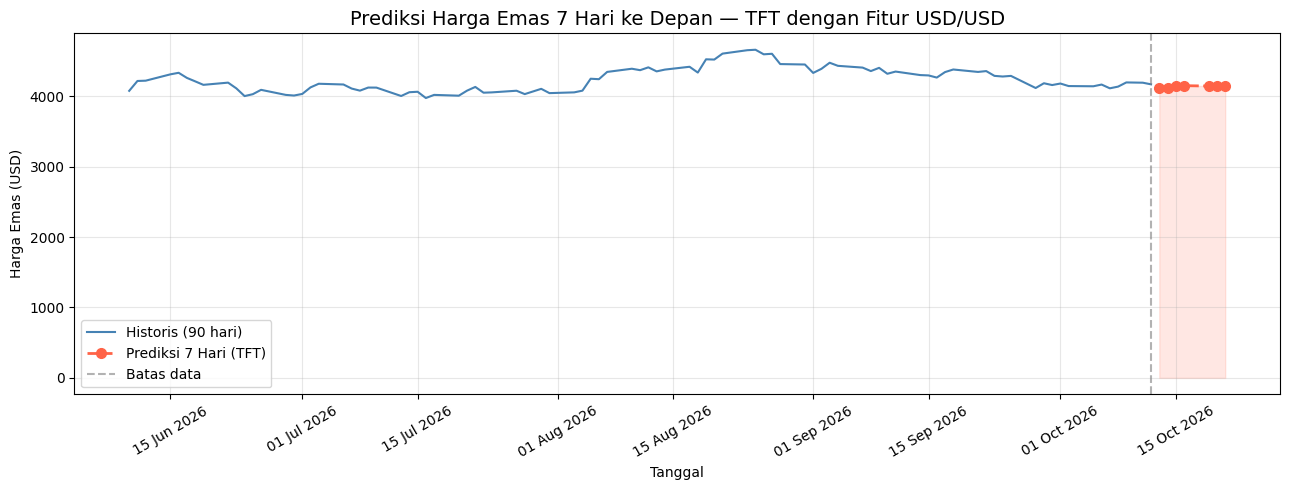


✅ Selesai!


In [26]:
# Membuat kanvas untuk memvisualisasikan prediksi harga emas periode mendatang.
fig, ax = plt.subplots(figsize=(13, 5))

# Mengambil data tanggal dan harga penutupan historis selama 90 hari terakhir.
hist_dates = df['date'].tail(90)
hist_close = df['close'].tail(90)

# Menampilkan pergerakan harga emas historis sebagai garis pembanding.
ax.plot(
    hist_dates,
    hist_close,
    color='steelblue',
    linewidth=1.5,
    label='Historis (90 hari)'
)

# Menampilkan hasil prediksi harga emas untuk tujuh hari kerja ke depan.
ax.plot(
    future_dates,
    future_values,
    'o--',
    color='tomato',
    linewidth=2,
    markersize=7,
    label='Prediksi 7 Hari (TFT)'
)

# Menandai batas antara periode historis dan periode prediksi.
ax.axvline(
    x=last_date,
    color='gray',
    linestyle='--',
    alpha=0.6,
    label='Batas data'
)

# Memberikan arsiran pada periode prediksi untuk memperjelas area hasil estimasi.
ax.fill_between(
    future_dates,
    future_values,
    alpha=0.15,
    color='tomato'
)

# Mengatur format label tanggal pada sumbu horizontal.
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b %Y'))

# Memutar label tanggal agar lebih mudah dibaca.
plt.xticks(rotation=30)

# Menambahkan judul dan label sumbu pada grafik.
ax.set_title(
    "Prediksi Harga Emas 7 Hari ke Depan — TFT dengan Fitur USD/USD",
    fontsize=14
)
ax.set_xlabel("Tanggal")
ax.set_ylabel("Harga Emas (USD)")

# Menampilkan legenda dan garis bantu untuk mempermudah pembacaan grafik.
ax.legend()
ax.grid(alpha=0.3)

# Mengatur tata letak grafik agar seluruh elemen terlihat dengan baik.
plt.tight_layout()

# Menyimpan grafik prediksi ke dalam file PNG.
plt.savefig(
    "tft_future_forecast.png",
    dpi=150,
    bbox_inches='tight'
)

# Menampilkan grafik prediksi harga emas.
plt.show()

# Menandai bahwa seluruh proses prediksi dan visualisasi telah selesai.
print("\n✅ Selesai!")